# Лабораторная работа №2

## Нейросетевой перевод на базе Hugging Face Transformers (MarianMT, NLLB)

**ФИО студента:** Асадова Хадижа Эльдаровна
**Группа:**  ИНФА_221
**Вариант:** 1 (**тот же, что в ЛР № 1** — работа сквозная; предметная область: предметная область: Информационные технологии: разработка ПО и DevOps)

---

**Цель:** развернуть NMT-пайплайн, исследовать субсловную токенизацию, батчинг, условную
кросс-энтропию и cross-attention, сравнить специализированную EN→RU модель **MarianMT**
с многоязычной **NLLB**.

**Максимум: 20 баллов**

| Критерий | Состав | Баллы |
|---|---|---:|
| Работоспособность пайплайна | MarianMT — 2 · NLLB — 2 · batching/loss/attention — 2 | **6** |
| Корректность лингвистической обработки | языковые коды и токенизация — 2 · объём корпуса (120+ сегментов, 100+ терминов) — 1 · glossary QA — 2 | **5** |
| Анализ ошибок и аргументация | 5+ различий — 2 · интерпретация loss/attention — 2 · вывод — 1 | **5** |
| Оформление и воспроизводимость | результаты и графики — 1 · README — 1 · зависимости — 1 · структура — 1 | **4** |

---

> **Прежде чем запускать код,** прочитайте три следующих раздела: «Суть работы за пять минут», «Связь с ЛР № 1 и место работы в курсе» и «Теоретическое обоснование». Без них блоки 5–8 превращаются в набор непонятных вызовов библиотеки, а интерпретация чисел в отчёте оказывается неверной — это самая частая причина потери баллов по критерию «Анализ ошибок и аргументация».

### Порядок выполнения

1. **Runtime → Change runtime type → T4 GPU.** Без GPU перевод 120 сегментов двумя моделями
   займёт часы.
2. Выполните блоки 0–1 (установка, окружение).
3. Блок 2 — положите в каталог `DATA` **свои** артефакты ЛР № 1: память переводов
   `variant_<N>.tmx` и терминологическую базу `variant_<N>.tbx` (либо их CSV-выгрузки
   `tm_segments_v<N>.csv` и `glossary_smartcat_v<N>.csv`). Блок 2.0 сам преобразует их во
   входные файлы работы; убедитесь, что проверка объёма даёт «ГОТОВО».
4. Реализуйте функции в блоках 3–8 вместо маркеров `# TODO`.
5. Запустите блок 9 — все автотесты должны пройти без `AssertionError`.
6. Выполните блоки 10–15: перевод корпуса, QA, сравнение, **графики**, отчёт.
7. Заполните вручную колонки `preferred` и `comment` — автоматический выбор модели их не
   заменяет.

### Обязательный минимум

| Требование | Значение |
|---|---|
| Сегментов в корпусе, переведённых **каждой** моделью | **120+** |
| Терминов в глоссарии, разобранных токенизаторами | **100+** |
| Пар `source` / `reference` для кросс-энтропии | 5+ |
| Пар для анализа cross-attention | 2+ |
| Режимы инференса | последовательный и пакетный |
| Содержательных различий с аргументацией | 5+ |
| Графиков в отчёте | 4+ |

> Если память переводов из ЛР № 1 меньше требуемого объёма, расширьте в своём ноутбуке ЛР № 1
> списки `PARALLEL_CORPUS` и `TERMS` и перегенерируйте `variant_<N>.tmx` и `variant_<N>.tbx`
> **до** начала этой работы: все дальнейшие выводы опираются на статистику, а на полутора
> десятках сегментов она недостоверна.

### Две особенности актуальных версий библиотек

* **`attn_implementation="eager"`.** Начиная с `transformers` 4.36 при PyTorch ≥ 2.1.1
  по умолчанию подключается ускоренная реализация внимания **SDPA**, которая не обязана
  сохранять веса: в зависимости от версии `outputs.cross_attentions` окажется пустым, и
  блок 7 упадёт с `IndexError: tuple index out of range`. Загружайте модель с явным
  `attn_implementation="eager"`.
* **Предупреждение `max_new_tokens` / `max_length`.** Безобидно (приоритет у
  `max_new_tokens`), но зашумляет вывод — логирование понижается в блоке 1.

## Суть работы


В ЛР № 1 вы собрали **ресурсы переводчика** в форматах CAT-систем: терминологическую базу `variant_<N>.tbx` и память переводов `variant_<N>.tmx` с параллельными сегментами, проверенными человеком. Сейчас те же самые файлы становятся входом: сегменты из памяти переводов прогоняются через **две нейросетевые системы машинного перевода**, терминология из TBX служит эталоном для контроля, а русская часть TMX — эталонным переводом для сравнения.

Работа отвечает на один практический вопрос: **можно ли доверить машине перевод текстов вашей предметной области с утверждённой терминологией — и что именно придётся проверять руками?**

### Четыре явления, которые вы исследуете

| Явление | Вопрос, на который отвечаем | Где в ноутбуке |
|---|---|---|
| **Субсловная токенизация** | Как модель «видит» ваши термины: целиком или обрывками? | блоки 4, 10 |
| **Батчинг** | Сколько стоит перевод по времени и как его ускорить? | блок 6 |
| **Условная кросс-энтропия** | Насколько «привычен» для модели утверждённый перевод? | блок 7 |
| **Cross-attention** | На какие слова оригинала модель смотрела, порождая каждое слово перевода? | блок 8 |

Дальше эти четыре наблюдения складываются в одно прикладное сравнение: **специализированная EN→RU модель MarianMT против многоязычной NLLB** — и в терминологический контроль по вашему глоссарию.

### Что это даёт педагогу как специалисту

Вы получаете не «кнопку перевода», а воспроизводимую процедуру: перевести учебный материал, измерить, где система систематически ошибается на терминах, и оценить объём обязательного постредактирования. Именно так выглядит подготовка локализованного учебного контента в реальной практике: машина делает черновик, человек отвечает за терминологию и смысл.

### Главный вывод, к которому ведёт работа

Беглость перевода и его правильность — **разные вещи**. Нейросеть выдаёт гладкий русский текст, в котором специальный термин может быть искажён, заменён общеупотребительным словом или передан описательно, — и всё это при безупречной грамматике. Найти такие места в переводе своего модуля и есть задача работы. Практическое следствие: терминологический контроль нельзя делегировать модели, он остаётся отдельным этапом работы редактора.

## Связь с ЛР № 1 и место работы в курсе

### Что вы сделали в ЛР № 1 и что из этого берётся сюда

В ЛР № 1 вы работали с форматами CAT-систем: разбирали терминологическую базу **TBX** (ISO 30042), память переводов **TMX** 1.4b, реализовали нечёткий поиск (Fuzzy Match и ICE) и подстановку терминов, а затем выгрузили результаты для Smartcat. На выходе получился комплект файлов — он и есть вход текущей работы.

| Артефакт ЛР № 1 | Что внутри | Во что превращается в ЛР № 2 | Где используется |
|---|---|---|---|
| `variant_<N>.tmx` | единицы перевода `<tu>`: `<seg>` на en и ru, `prop[domain]`, порядок сегментов | `segments_en.csv` (`segment_id`, `source`) и `aligned_reference.csv` (+ `reference`) | вход обеих моделей; эталон для кросс-энтропии и сравнения |
| `variant_<N>.tbx` | `termEntry` → `langSet` en/ru, `<tig>` и `<ntig><termGrp>` | `glossary.csv` (`en`, `ru`) | анализ токенизации и терминологический контроль |
| `glossary_smartcat_v<N>.csv` | `Source (en)`, `Target (ru)`, `Comment` | то же, что TBX (резервный путь) | если XML-файлы не сохранились |
| `tm_segments_v<N>.csv` | `tuid`, `source_segment`, `target_segment`, `domain` | то же, что TMX (резервный путь) | если XML-файлы не сохранились |
| `fuzzy_report_v<N>.csv` | отчёт Fuzzy Match / ICE | в расчётах не участвует | пригодится в выводах: сравнение TM-подстановки и NMT |

Соответствие полей буквальное: `tuid` → `segment_id`, `<seg>` на английском → `source`, `<seg>` на русском → `reference`, английский `<term>` → `en`, русский `<term>` → `ru`. Преобразование выполняет **блок 2.0** — писать его не нужно, но полезно прочитать: там видно, как из XML получается таблица.

### Почему именно эти файлы

* **TMX — это готовый параллельный корпус**, проверенный человеком. Без него нечем считать условную кросс-энтропию и не с чем сравнивать вывод моделей.
* **TBX — утверждённая терминология**. Без неё нечего проверять в терминологическом контроле, а именно он показывает главную слабость нейросетевого перевода.
* **Порядок сегментов в TMX сохраняется** — тот же порядок, который в ЛР № 1 нужен был для контекстного совпадения (ICE). Здесь он даёт связный документ, а не случайный набор фраз.

### Логика курса: три взгляда на одну задачу

```
ЛР № 1  Память переводов и CAT         ЛР № 2  Нейросетевой перевод        далее по курсу
──────────────────────────────         ────────────────────────────        ──────────────────────
TBX: терминология              ───►    токенизация терминов, QA      ───►  метрики качества
TMX: параллельные сегменты     ───►    вход моделей + эталон               BLEU, chrF, COMET
Fuzzy Match / ICE: повторное           кросс-энтропия, внимание            постредактирование
использование перевода                 сравнение Marian и NLLB
```

ЛР № 1 отвечала на вопрос «как **повторно использовать** уже выполненный перевод», ЛР № 2 — «что будет, если перевод **породит модель**», следующая работа курса — «**насколько хорошо** это получилось». Отсюда естественный сюжет для выводов: сегмент с совпадением 100 % (ICE) в ТМ не нуждается в машинном переводе вовсе, а для сегментов без совпадения выбор стоит между NMT с постредактированием и переводом с нуля.

### Объём данных: что делать, если ТМ из ЛР № 1 маленькая

ЛР № 1 не требовала большого корпуса: в эталонном решении получилось 14 единиц перевода и 18 терминов. Для ЛР № 2 нужно **120 сегментов и 100 терминов** — иначе доли соблюдения глоссария и различия моделей статистически недостоверны.

Порядок действий: откройте **свой** ноутбук ЛР № 1, расширьте списки `PARALLEL_CORPUS` и `TERMS` материалами той же предметной области, перегенерируйте `variant_<N>.tmx` и `variant_<N>.tbx` и перенесите их сюда. Код ЛР № 1 при этом не меняется — меняются только данные. Русские соответствия в расширенной части проверяются вручную: `reference` должен остаться переводом, подтверждённым человеком, иначе расчёт кросс-энтропии теряет смысл.

> **О номерах вариантов.** Предметная область берётся из **вашей** ЛР № 1 (в TMX она записана в `prop[@type="domain"]`, в TBX — в `descrip[@type="subjectField"]`), и блок 2.0 печатает её при загрузке. Если нумерация вариантов в таблицах двух работ расходится, ориентируйтесь на предметную область своего комплекта TBX/TMX, а не на номер.

## Теоретическое обоснование

Ниже — минимум теории, который нужен, чтобы понимать, что именно считает код, и корректно интерпретировать числа. Каждый пункт привязан к конкретному блоку ноутбука.

### 1. Что такое нейросетевой перевод (NMT)

Современный перевод — это задача **sequence-to-sequence**: модель получает последовательность токенов исходного языка и порождает последовательность токенов целевого. Архитектура обеих используемых моделей — **энкодер-декодер на основе трансформера** (Vaswani et al., 2017):

* **энкодер** читает весь исходный сегмент и строит для каждой позиции векторное представление с учётом контекста (self-attention);
* **декодер** порождает перевод **по одному токену слева направо**; на каждом шаге он смотрит на уже порождённую часть перевода (self-attention) и на представления оригинала (**cross-attention**);
* выход декодера — распределение вероятностей по всему словарю; из него выбирается следующий токен.

Ключевое отличие от статистического перевода (SMT), с которым знакомились ранее в курсе: в SMT таблицы фраз и модель выравнивания строились явно, а здесь и «словарь соответствий», и «правила перестановки» существуют только как веса сети. Отсюда два следствия, которые вы увидите на практике: система никогда не скажет «не знаю» и выдаст беглый текст даже там, где ошибается.

### 2. Декодирование: как из вероятностей получается текст

Генерация — отдельный алгоритм поверх модели. В работе используется **лучевой поиск (beam search)**: одновременно удерживается несколько гипотез перевода (`num_beams`), на каждом шаге они расширяются и отбираются лучшие по суммарной логарифмической вероятности. Параметры, которые встретятся в коде:

| Параметр | Смысл | Практическое следствие |
|---|---|---|
| `num_beams` | ширина луча | больше — качественнее и медленнее; при 1 это жадный поиск |
| `max_new_tokens` | ограничение длины вывода | защита от зацикливания; приоритетнее `max_length` из конфигурации модели |
| `length_penalty` | штраф за длину | без него beam search систематически предпочитает короткие переводы |
| `do_sample` | случайная выборка | в работе **выключена**: нужна воспроизводимость |

Поэтому перевод в этой работе **детерминирован**: при одних и тех же входе и параметрах результат повторяется. Зафиксированное зерно и `model.eval()` (отключение dropout) — часть того же требования воспроизводимости.

### 3. Субсловная токенизация (блоки 4 и 10)

Словарь модели конечен (у MarianMT — 62 518 единиц, у NLLB — 256 204), а терминология в информатике не ограничена. Решение — **открытый словарь**: редкое слово собирается из частотных фрагментов.

Два основных алгоритма:

* **BPE** (Sennrich et al., 2016) — жадное слияние самых частых пар символов, пока не наберётся заданный размер словаря;
* **Unigram LM** (Kudo, 2018) — вероятностная модель: избыточный словарь постепенно сокращается, остаются единицы, максимизирующие правдоподобие корпуса.

**SentencePiece** (Kudo & Richardson, 2018) — это не алгоритм, а библиотека-обёртка, которая умеет и BPE, и Unigram и работает прямо с сырым текстом, кодируя пробел символом `▁`. Поэтому фраза «Marian = BPE, а NLLB = SentencePiece» некорректна: она противопоставляет алгоритм и инструмент. Правильная формулировка проверяется по классу токенизатора и карточке модели; в документации Hugging Face токенизатор NLLB описан как основанный на **Unigram**, у MarianMT используется собственная реализация поверх SentencePiece.

Что отсюда важно для работы:

1. **Токен ≠ морфема.** Границы получены статистически по корпусу, а не морфологическим анализом: `▁as y mp to tic` не соответствует ни одной морфеме.
2. **Разные словари — разные границы** у одного слова (`▁computation al` против `▁comput ational`), значит, дробление — свойство конкретной модели, а не языка.
3. **Размер словаря не определяет качество дробления на вашем домене.** У NLLB словарь вчетверо больше, но ёмкость распределена между 200 языками, поэтому на английской технической лексике он дробит сильнее. Это частный случай **«проклятия многоязычности»**: при фиксированной ёмкости модели добавление языков ухудшает результат по каждому из них (Conneau et al., 2020).
4. Сильно дробящиеся термины — **кандидаты на нестабильный перевод**; связь дробления и нарушений глоссария вы проверите в блоке 12.

### 4. Условная кросс-энтропия и перплексия (блок 7)

$$\mathcal{L} = -\frac{1}{T}\sum_{t=1}^{T}\log P\left(y_t \mid y_{1:t-1}, x\right)$$

Модель получает исходный сегмент $x$ и **готовую** целевую строку $y$ и на каждом шаге оценивает вероятность фактического следующего токена при условии правильного префикса. Такой режим называется **teacher forcing**: это не генерация, а оценка уже существующей строки — тот же расчёт, что и при обучении.

Технические детали, влияющие на интерпретацию:

* усреднение идёт по токенам целевой строки (паддинг исключается меткой `-100`), поэтому величина **нормирована на длину**;
* удобная эквивалентная форма — **перплексия** $PPL = e^{\mathcal{L}}$: «из скольких равновероятных вариантов модель фактически выбирала». Loss 0.58 — это PPL ≈ 1.8, loss 1.14 — PPL ≈ 3.1;
* `loss_own_output` систематически ниже `loss_reference`: модель по построению считает более вероятным то, что сама и породила. Это свойство декодера, а не превосходство над переводчиком-человеком.

**Чем кросс-энтропия не является.** Это не метрика качества перевода. Она измеряет вероятность конкретной строки при конкретной модели и **несопоставима между моделями с разными словарями**: разные токенизаторы дают разное $T$ и разное пространство событий. Для оценки качества нужны BLEU, chrF и COMET — они появятся в следующей работе курса. Полезная же роль loss здесь диагностическая: высокий `loss_reference` отмечает сегменты, где утверждённый перевод расходится с «привычным» для модели, — обычно это места с терминологией.

### 5. Cross-attention (блок 8)

Веса внимания декодера к позициям оригинала образуют тензор формы `[batch, heads, target_len, source_len]`. После усреднения по головам получается матрица, внешне похожая на матрицу выравнивания слов из статистического перевода.

Как её корректно читать:

* **диагональная структура** говорит о том, что порядок порождения в целом следует порядку оригинала; отклонения от диагонали отмечают перестановки;
* заметная доля массы регулярно уходит на **служебные токены** (`</s>`) — это не переводческое соответствие, а поведение сети;
* **attention — диагностический сигнал, а не объяснение**. В литературе это прямо показано: веса внимания не обязаны совпадать с важностью входов (Jain & Wallace, 2019), возможны альтернативные распределения весов с тем же предсказанием (Wiegreffe & Pinter, 2019), а роли голов различаются и часть из них избыточна (Voita et al., 2019). Утверждение «эта голова выучила правило перевода» из одной тепловой карты не следует.

**Техническое условие.** Веса внимания возвращает только «наивная» реализация (`eager`). Начиная с `transformers` 4.36 при PyTorch ≥ 2.1.1 по умолчанию подключается ускоренная реализация **SDPA**, которая сохранять веса не обязана: в зависимости от версии библиотека либо сама откатывается на `eager` с предупреждением, либо возвращает пустой кортеж `cross_attentions`, и код падает с `IndexError`. Поэтому модель загружается с явным `attn_implementation="eager"`.

### 6. Батчинг, паддинг и время инференса (блок 6)

Пакетная обработка ускоряет перевод, потому что графический процессор эффективен на крупных матричных операциях: вместо множества мелких вызовов выполняется один большой. Плата за это — **паддинг**: короткие сегменты дополняются до длины самого длинного в пачке, и часть вычислений тратится на заполнители. Отсюда два наблюдаемых эффекта:

* **насыщение** — при росте размера пачки прирост скорости падает;
* **возможные расхождения результата** между режимами: паддинг меняет числа в маскируемых позициях, и beam search на границе может выбрать другую гипотезу. Это не ошибка реализации, но причина фиксировать режим инференса в отчёте.

Различайте **задержку** (время одного сегмента, важна для интерактивного перевода) и **пропускную способность** (сегментов в секунду, важна для пакетной локализации модуля). Батчинг улучшает второе.

### 7. Специализированная модель против многоязычной (блоки 9, 13)

| | MarianMT `Helsinki-NLP/opus-mt-en-ru` | NLLB `facebook/nllb-200-distilled-600M` |
|---|---|---|
| Охват | одна пара EN→RU | 200 языков |
| Параметры | ≈ 76 млн | ≈ 615 млн |
| Происхождение | обучена на корпусах OPUS (Tiedemann & Thottingal, 2020) | дистиллированная версия большой модели NLLB-200 (NLLB Team, 2022) |
| Направление перевода | задано самой моделью | задаётся **кодами языков**: `src_lang` и `forced_bos_token_id` |

**Дистилляция** означает, что компактная модель обучалась воспроизводить поведение более крупной: это способ сохранить значительную часть качества при меньших ресурсах.

**Механизм языковых кодов** стоит понимать буквально: у многоязычной модели декодер начинает генерацию со специального токена целевого языка. Если его не задать, язык результата не определён — в эталонном прогоне без `forced_bos_token_id` модель выдала испанский перевод. Коды берутся из схемы FLORES-200 (`eng_Latn`, `rus_Cyrl`) и являются частью контракта модели, а не декоративным параметром.

### 8. Терминологический контроль (блок 12)

Для учебного модуля единообразие терминологии важнее стилистической гладкости: если в одном абзаце «вычислительная сложность», а в другом «расчётная сложность», студент решит, что речь о разных понятиях. NMT-модель общего назначения такого единообразия не гарантирует — она оптимизирует вероятность строки, а не соответствие вашему глоссарию.

Отсюда требования к процедуре QA:

* **знаменатель** — число фактических вхождений терминов в исходные сегменты, а не все пары «сегмент × термин», иначе доля соблюдения искусственно завышается;
* **русская морфология** ломает точное строковое сравнение («сложность» → «сложности», «сложностью»), поэтому сравнение ведётся по основе, а каждое срабатывание подтверждается вручную;
* строковая проверка даёт и **ложные срабатывания** (корректный синоним, смена части речи при перестройке предложения), и **пропуски** (термин передан описательно). Автоматическая цифра без ручного подтверждения в отчёт не выносится.

В профессиональной практике этот этап стандартизован: требования к процессу перевода описывает ISO 17100:2015, а к полному постредактированию машинного перевода — ISO 18587:2017. Ваша колонка `confirmed` — учебный аналог того самого постредакторского решения.

### 9. Типология различий и ошибок (блоки 13–14)

Чтобы сравнение моделей не сводилось к «мне больше нравится», различия классифицируются. Удобная опора — типология MQM (Lommel et al., 2014), из которой для этой работы достаточно четырёх категорий:

| Категория | Что это | Как выглядит на практике |
|---|---|---|
| **Точность (accuracy)** | искажение смысла оригинала | многозначное слово переведено неверным значением, отрицание или число потеряны |
| **Терминология** | отклонение от утверждённого в ЛР № 1 глоссария | вместо принятого термина — синоним, калька или описательный оборот |
| **Беглость (fluency)** | грамматика и согласование | придаточное отнесено не к тому члену предложения, нарушено управление |
| **Стиль и синтаксис** | допустимая, но нежелательная перестройка | термин из подлежащего определения превращён в обстоятельство |

Именно эта классификация превращает колонку `comment` из мнения в аргумент.

## Блок 0. Установка зависимостей

`torch` в Colab предустановлен. Ставим `transformers`, `sentencepiece` (нужен токенизатору
NLLB) и `sacremoses` (предобработка MarianMT).

In [72]:
!pip install -q "transformers>=4.40" sentencepiece sacremoses

## Блок 1. Окружение и структура каталогов

Ячейка готова — менять её не нужно. Зафиксированное зерно и вывод версий обязательны для
воспроизводимости (критерий 4).

In [73]:
from __future__ import annotations

import json
import platform
import random
import time
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

transformers.logging.set_verbosity_error()   # убирает предупреждение о max_length

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

BASE = Path("/content/lab02") if Path("/content").exists() else Path.cwd() / "lab02"
DATA = BASE / "data"
RESULTS = BASE / "results"
FIGURES = BASE / "figures"
for folder in (DATA, RESULTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MARIAN_NAME = "Helsinki-NLP/opus-mt-en-ru"
NLLB_NAME = "facebook/nllb-200-distilled-600M"
SRC_LANG, TGT_LANG = "eng_Latn", "rus_Cyrl"

MIN_SEGMENTS, MIN_TERMS = 120, 100

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

ENVIRONMENT = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "-",
}
for key, value in ENVIRONMENT.items():
    print(f"{key:>13}: {value}")
print(f"{'base_dir':>13}: {BASE}")
if DEVICE.type != "cuda":
    print("\nВНИМАНИЕ: GPU не подключён. Runtime -> Change runtime type -> T4 GPU.")

       python: 3.13.16
        torch: 2.11.0+cu130
 transformers: 5.20.2
       device: cuda
          gpu: Tesla T4
     base_dir: /content/lab02


## Блок 2. Данные: артефакты ЛР № 1 (TBX и TMX)

**Что нужно подготовить.** Вход работы — файлы, которые вы уже сдавали в ЛР № 1:

| Файл ЛР № 1 | Обязателен | Что из него берётся |
|---|---|---|
| `variant_<N>.tmx` — память переводов | да (или CSV-замена) | параллельные сегменты: английский `<seg>` → `source`, русский `<seg>` → `reference`, `tuid` → `segment_id` |
| `variant_<N>.tbx` — терминологическая база | да (или CSV-замена) | термины: английский `<term>` → `en`, русский `<term>` → `ru` |
| `tm_segments_v<N>.csv` | резервный путь | колонки `tuid`, `source_segment`, `target_segment` |
| `glossary_smartcat_v<N>.csv` | резервный путь | колонки `Source (en)`, `Target (ru)` |

XML-файлы предпочтительнее: в них сохранены порядок сегментов, коды языков и предметная область (`prop[@type="domain"]`), а CSV-выгрузка часть этого теряет.

**Как положить файлы в среду.** В ячейке блока 2.0 закомментированы две заготовки: загрузка с компьютера через `files.upload()` и копирование из Google Drive. Второй способ удобнее: файлы переживут перезапуск среды Colab.

**Что произойдёт дальше.** Блок 2.0 (адаптер) прочитает ваши TBX и TMX и соберёт три файла в каталоге `DATA`: `segments_en.csv`, `glossary.csv`, `aligned_reference.csv`. Следующая ячейка их прочитает и проверит структуру и объём. Если артефакты ЛР № 1 не найдены, создаётся **демонстрационный** мини-набор: он годится только для проверки автотестов, сдавать работу на нём нельзя.

**Требуемый объём: 120 сегментов и 100 терминов.** В ЛР № 1 корпус мог быть меньше (в эталоне — 14 сегментов и 18 терминов). Тогда откройте свой ноутбук ЛР № 1, дополните списки `PARALLEL_CORPUS` и `TERMS` материалами той же предметной области, перегенерируйте `variant_<N>.tmx` и `variant_<N>.tbx` и вернитесь сюда. Русские соответствия в добавленной части проверьте вручную: `reference` должен остаться переводом, подтверждённым человеком.

**На что смотреть в выводе.** Имена источников, число сегментов и терминов, предметная область из вашего TMX и строку «ГОТОВО» проверки объёма.

### Блок 2.0. Адаптер артефактов ЛР № 1

> Ячейка ниже содержит готовый адаптер: функции `tmx_to_pairs()` и `tbx_to_glossary()` разбирают XML стандартов TMX 1.4b и TBX (ISO 30042) теми же приёмами, что и ЛР № 1, а `build_lab02_inputs()` собирает три входных файла работы.

Ячейка готова — менять её не нужно. Если файлы ЛР № 1 не найдены, адаптер сообщит об этом и следующая ячейка создаст демонстрационный набор для проверки автотестов.

In [74]:
#  Генерация variant_1.tbx и variant_1.tmx (120 терминов / 120 сегментов)
#  Файлы кладутся в DATA, чтобы блок 2.0 (адаптер) их подхватил.
import os
import xml.etree.ElementTree as ET
from typing import Dict, List, Sequence, Tuple

XML_LANG = "{http://www.w3.org/XML/1998/namespace}lang"
VARIANT = 1
SUBJECT_FIELD = "Информационные технологии: разработка ПО и DevOps"
DOMAIN = SUBJECT_FIELD

TBX_PATH = DATA / f"variant_{VARIANT}.tbx"
TMX_PATH = DATA / f"variant_{VARIANT}.tmx"


TERMS: List[Dict[str, str]] = [
    {"en": "deployment", "ru": "развертывание", "pos": "noun",
     "def_en": "An implementation, or putting into use, of something."},
    {"en": "continuous integration", "ru": "непрерывная интеграция", "pos": "noun",
     "def_en": "The practice of merging all branches to a shared mainline several times a day."},
    {"en": "deployment pipeline", "ru": "конвейер развертывания", "pos": "noun",
     "def_en": "An automated implementation of your application's build, deploy, test, and release process."},
    {"en": "installer", "ru": "инсталлятор", "pos": "noun",
     "def_en": "A program that installs software and prepares it for use."},
    {"en": "binary code", "ru": "бинарный код", "pos": "noun",
     "def_en": "A code that uses only the numbers 0 and 1."},
    {"en": "feedback", "ru": "обратная связь", "pos": "noun",
     "def_en": "Critical assessment of a process or activity or of their results."},
    {"en": "web server", "ru": "веб-сервер", "pos": "noun",
     "def_en": "Software that delivers web pages and other documents to browsers using the HTTP protocol."},
    {"en": "release", "ru": "релиз", "pos": "noun",
     "def_en": "The distribution of an initial or new and upgraded version of a computer software product."},
    {"en": "manually", "ru": "вручную", "pos": "adverb",
     "def_en": "By hand, using your hands."},
    {"en": "result", "ru": "результат", "pos": "noun",
     "def_en": "A positive result or consequence."},
    {"en": "documentation", "ru": "документация", "pos": "noun",
     "def_en": "Documents that explain the operation of a particular software program."},
    {"en": "development team", "ru": "команда разработчиков", "pos": "noun",
     "def_en": "Team of software development experts."},
    {"en": "automated", "ru": "автоматизированный", "pos": "adjective",
     "def_en": "Carried out by machines or computers without needing human control."},
    {"en": "tester", "ru": "тестировщик", "pos": "noun",
     "def_en": "A person or a machine that tests something."},
    {"en": "application", "ru": "приложение", "pos": "noun",
     "def_en": "A computer program that is designed for a particular purpose."},
    {"en": "version control", "ru": "управление версиями", "pos": "noun",
     "def_en": "The process of maintaining a database of all the source code and related files in a software development project to keep track of changes made during the project."},
    {"en": "URL", "ru": "URL-адрес", "pos": "noun",
     "def_en": "Abbreviation for uniform resource locator: a website address."},
    {"en": "rollback", "ru": "откат", "pos": "noun",
     "def_en": "An operation which returns a database, or group of records in a database, to a previous state."},
    {"en": "cycle time", "ru": "продолжительность цикла", "pos": "noun",
     "def_en": "The time it takes from deciding to make a change, whether a bugfix or a feature, to having it available to users."},
    {"en": "configuration", "ru": "конфигурация", "pos": "noun",
     "def_en": "The way in which all the equipment that makes up a computer system is set to operate."},
    {"en": "component", "ru": "компонент", "pos": "noun",
     "def_en": "One of the parts of a system, process, or machine."},
    {"en": "executable code", "ru": "исполняемый код", "pos": "noun",
     "def_en": "Instructions for a computer in a form the computer can directly use."},
    {"en": "source code", "ru": "исходный код", "pos": "noun",
     "def_en": "Human-readable instructions in a programming language, to be transformed into machine instructions by a compiler, assembler or other translator, or to be carried out directly by an interpreter."},
    {"en": "performance", "ru": "производительность", "pos": "noun",
     "def_en": "The amount of useful work accomplished by a computer system compared to the time and resources used."},
    {"en": "customer", "ru": "заказчик", "pos": "noun",
     "def_en": "A person or an organization that buys a product or service."},
    {"en": "fault", "ru": "ошибка", "pos": "noun",
     "def_en": "Something that is wrong with a machine or system."},
    {"en": "user interface", "ru": "пользовательский интерфейс", "pos": "noun",
     "def_en": "The way in which the information on a computer, phone, etc. and instructions on how to use it are arranged on the screen and shown to the user."},
    {"en": "hardware", "ru": "оборудование", "pos": "noun",
     "def_en": "Equipment or the physical and electronic parts of a computer."},
    {"en": "lean manufacturing", "ru": "бережливое производство", "pos": "noun",
     "def_en": "The business of producing goods in large numbers using methods that avoid waste and reduce the time taken."},
    {"en": "version", "ru": "версия", "pos": "noun",
     "def_en": "Particular form of something that is slightly different from other forms of the same thing."},
    {"en": "button", "ru": "кнопка", "pos": "noun",
     "def_en": "A small, sometimes circular object that you press to operate a device or a machine, or an area on a computer screen that looks and acts like one of these."},
    {"en": "flexibility", "ru": "гибкость", "pos": "noun",
     "def_en": "The ability to change or be changed easily according to the situation."},
    {"en": "analyst", "ru": "аналитик", "pos": "noun",
     "def_en": "Someone whose job is to study or examine something in detail, in order to discover or understand more about it and often to make predictions relating to it."},
    {"en": "configuration management", "ru": "управление конфигурациями", "pos": "noun",
     "def_en": "The process by which all artifacts relevant to your project, and the relationships between them, are stored, retrieved, uniquely identified, and modified."},
    {"en": "compiler", "ru": "компилятор", "pos": "noun",
     "def_en": "A computer program that changes instructions into machine language."},
    {"en": "release candidate", "ru": "релиз-кандидат", "pos": "noun",
     "def_en": "A version of a program that is nearly ready for release but may still have a few bugs."},
    {"en": "defect", "ru": "дефект", "pos": "noun",
     "def_en": "A fault that spoils something or causes it not to work correctly."},
    {"en": "functionality", "ru": "функциональность", "pos": "noun",
     "def_en": "Any or all of the operations performed by a piece of equipment or a software program."},
    {"en": "collaborate", "ru": "сотрудничать", "pos": "verb",
     "def_en": "To work together with others to achieve a common goal."},
    {"en": "fundamentals", "ru": "основы", "pos": "noun",
     "def_en": "The main or most important rules or parts."},
    {"en": "stack", "ru": "стек", "pos": "noun",
     "def_en": "A way of storing data on a computer so that the last piece of data to be stored is the first one to be found by the computer."},
    {"en": "snapshot", "ru": "снимок", "pos": "noun",
     "def_en": "A file or set of files captured at a particular time, capable of being reloaded to restore the earlier state."},
    {"en": "settings", "ru": "параметры", "pos": "noun",
     "def_en": "Personal configuration options that allow users to customize their applications or operating system."},
    {"en": "store", "ru": "хранить", "pos": "verb",
     "def_en": "To put or keep something somewhere until it is needed."},
    {"en": "procedures", "ru": "процедуры", "pos": "noun",
     "def_en": "Set of instructions in a computer program that does a particular task."},
    {"en": "project managers", "ru": "менеджеры проекта", "pos": "noun",
     "def_en": "Someone whose job is to plan a piece of work or activity and organize the work of all the people involved in it."},
    {"en": "file", "ru": "файл", "pos": "noun",
     "def_en": "Information stored on a computer as one unit with one name."},
    {"en": "subsystems", "ru": "подсистемы", "pos": "noun",
     "def_en": "A system that forms part of a larger system."},
    {"en": "virtual machines", "ru": "виртуальные машины", "pos": "noun",
     "def_en": "Computer system that is created by software on one computer to copy the operations performed by a separate computer."},
    {"en": "delete", "ru": "удалять", "pos": "verb",
     "def_en": "To remove data, documents, programs, etc. from a computer."},
    {"en": "branch", "ru": "ветвь", "pos": "noun",
     "def_en": "A part of something larger."},
    {"en": "description", "ru": "описание", "pos": "noun",
     "def_en": "Something that tells you what something or someone is like."},
    {"en": "debugging", "ru": "отладка", "pos": "noun",
     "def_en": "To remove bugs or mistakes from a computer program."},
    {"en": "libraries", "ru": "библиотеки", "pos": "noun",
     "def_en": "A collection of subprograms used to develop software."},
    {"en": "modules", "ru": "модули", "pos": "noun",
     "def_en": "A section of a program, a subroutine."},
    {"en": "copies", "ru": "копии", "pos": "noun",
     "def_en": "Something that is exactly like another thing."},
    {"en": "interpreted language", "ru": "интерпретируемый язык", "pos": "noun",
     "def_en": "Programming language for which most of its implementations execute instructions directly."},
    {"en": "external", "ru": "внешние", "pos": "adjective",
     "def_en": "Outside of something, on the exterior."},
    {"en": "correlate", "ru": "согласовывать", "pos": "verb",
     "def_en": "To compare things and bring them into a relation having corresponding characteristics."},
    {"en": "split", "ru": "разбить", "pos": "verb",
     "def_en": "To divide into two or more parts."},
    {"en": "recompilation", "ru": "перекомпиляция", "pos": "noun",
     "def_en": "Compiling a computer program for a second, third, etc. time."},
    {"en": "run time", "ru": "время выполнения", "pos": "noun",
     "def_en": "The time during which a program is executing."},
    {"en": "pitfalls", "ru": "ловушки", "pos": "noun",
     "def_en": "Unexpected danger or difficulty."},
    {"en": "programming languages", "ru": "языки программирования", "pos": "noun",
     "def_en": "A set of rules, words, etc. that are used for writing computer programs."},
    {"en": "directory", "ru": "каталог", "pos": "noun",
     "def_en": "A structured listing of the names and characteristics of the files on a storage device."},
    {"en": "repository", "ru": "хранилище", "pos": "noun",
     "def_en": "A place where something is deposited, as for storage, safekeeping, or preservation."},
    {"en": "filesystem", "ru": "файловая система", "pos": "noun",
     "def_en": "A method of organizing blocks on a storage device into files and directories."},
    {"en": "digital certificates", "ru": "цифровые сертификаты", "pos": "noun",
     "def_en": "Digital documents that are commonly used for authentication and to help secure information on a network."},
    {"en": "encrypted", "ru": "зашифрованный", "pos": "adjective",
     "def_en": "Converted into a coded form."},
    {"en": "authentication", "ru": "аутентификация", "pos": "noun",
     "def_en": "Process of verifying identity or validity."},
    {"en": "remotely", "ru": "удаленно", "pos": "adverb",
     "def_en": "From a distance."},
    {"en": "change history", "ru": "история изменений", "pos": "noun",
     "def_en": "Information that is maintained about changes made in past editing sessions."},
    {"en": "on demand", "ru": "по требованию", "pos": "adverb",
     "def_en": "Whenever needed or requested."},
    {"en": "cluster", "ru": "кластер", "pos": "noun",
     "def_en": "A group of computers connected together to work as one larger computer and to improve their performance."},
    {"en": "smoke tests", "ru": "дымовые тесты", "pos": "noun",
     "def_en": "Basic test to ensure a system won't fail on start."},
    {"en": "installation", "ru": "инсталляция", "pos": "noun",
     "def_en": "Act of setting up equipment or software."},
    {"en": "lifecycle", "ru": "жизненный цикл", "pos": "noun",
     "def_en": "Series of developments from beginning to end of usefulness."},
    {"en": "infrastructure", "ru": "инфраструктура", "pos": "noun",
     "def_en": "The equipment, software, etc. that a computer system needs in order to operate and communicate with other computers."},
    {"en": "file descriptors", "ru": "дескрипторы", "pos": "noun",
     "def_en": "Stored information that names or identifies something in a system."},
    {"en": "check-in", "ru": "регистрация изменения", "pos": "noun",
     "def_en": "The act of committing a change to the version control system."},
    {"en": "environment", "ru": "среда", "pos": "noun",
     "def_en": "The system in which a computer or computer program operates."},
    {"en": "software packages", "ru": "пакеты ПО", "pos": "noun",
     "def_en": "Suite of programs working together for tasks."},
    {"en": "topology", "ru": "топология", "pos": "noun",
     "def_en": "Arrangement of nodes in a communications network."},
    {"en": "baseline", "ru": "базовая среда", "pos": "noun",
     "def_en": "An environment that is in a properly deployed state."},
    {"en": "from scratch", "ru": "с нуля", "pos": "adverb",
     "def_en": "From the beginning."},
    {"en": "working state", "ru": "работоспособное состояние", "pos": "noun",
     "def_en": "Good condition or operational state."},
    {"en": "command line", "ru": "командная строка", "pos": "noun",
     "def_en": "Interface for typing text commands to a computer."},
    {"en": "codebase", "ru": "кодовая база", "pos": "noun",
     "def_en": "The body of source code (and possibly auxiliary data files) used to create a particular computer program."},
    {"en": "unit tests", "ru": "модульные тесты", "pos": "noun",
     "def_en": "Tests of a single component of software."},
    {"en": "network", "ru": "сеть", "pos": "noun",
     "def_en": "Number of computers that are connected together so that they can share information."},
    {"en": "component tests", "ru": "тесты компонентов", "pos": "noun",
     "def_en": "Tests of the behavior of several components of the application."},
    {"en": "revert", "ru": "отменить", "pos": "verb",
     "def_en": "Return to a previous state or condition."},
    {"en": "extreme programming", "ru": "экстремальное программирование", "pos": "noun",
     "def_en": "A software engineering methodology prescribing a set of daily stakeholder practices taken to extreme levels."},
    {"en": "refactoring", "ru": "рефакторинг", "pos": "noun",
     "def_en": "Making a series of small, incremental changes that improve your code without changing your application's behavior."},
    {"en": "architecture", "ru": "архитектура", "pos": "noun",
     "def_en": "Structure and organization of computer systems."},
    {"en": "productivity", "ru": "продуктивность", "pos": "noun",
     "def_en": "State of being efficient and productive."},
    {"en": "reports", "ru": "отчеты", "pos": "noun",
     "def_en": "A spoken or written description of an event or situation."},
    {"en": "workload", "ru": "нагрузка", "pos": "noun",
     "def_en": "The amount of work assigned to a particular worker."},
    {"en": "automation", "ru": "автоматизация", "pos": "noun",
     "def_en": "The process of making a system or process operate without human intervention."},
    {"en": "risk", "ru": "риск", "pos": "noun",
     "def_en": "The possibility that something unpleasant or dangerous might happen."},
    {"en": "autonomic", "ru": "автономный", "pos": "adjective",
     "def_en": "Able to operate independently."},
    {"en": "ownership", "ru": "владение", "pos": "noun",
     "def_en": "The state or fact of owning something."},
    {"en": "trunk", "ru": "магистраль", "pos": "noun",
     "def_en": "The main development branch in a version control system."},
    {"en": "branch by abstraction", "ru": "ветвление по абстракции", "pos": "noun",
     "def_en": "A technique to make large-scale changes to an application by creating an abstraction layer."},
    {"en": "methodology", "ru": "методология", "pos": "noun",
     "def_en": "A system of methods used in a particular area of study or activity."},
    {"en": "production environment", "ru": "рабочая среда", "pos": "noun",
     "def_en": "The environment where software is running and being used by end-users."},
    {"en": "testing environment", "ru": "тестовая среда", "pos": "noun",
     "def_en": "An environment used for testing software before it is released."},
    {"en": "monitoring", "ru": "мониторинг", "pos": "noun",
     "def_en": "To watch and check a situation carefully for a period of time in order to discover something about it."},
    {"en": "optimization", "ru": "оптимизация", "pos": "noun",
     "def_en": "The process of making something as good or effective as possible."},
    {"en": "deployment rollback", "ru": "откат развертывания", "pos": "noun",
     "def_en": "The process of reverting to a previous version of software in a production environment."},
    {"en": "delivery", "ru": "поставка", "pos": "noun",
     "def_en": "The act of providing something to a person or place."},
    {"en": "cost", "ru": "стоимость", "pos": "noun",
     "def_en": "The amount of money needed to buy, do, or make something."},
    {"en": "quality", "ru": "качество", "pos": "noun",
     "def_en": "How good or bad something is."},
    {"en": "reduction", "ru": "сокращение", "pos": "noun",
     "def_en": "The act of making something shorter or smaller."},
    {"en": "effectiveness", "ru": "эффективность", "pos": "noun",
     "def_en": "The ability to produce a desired result."},
    {"en": "stage", "ru": "стадия", "pos": "noun",
     "def_en": "A particular point in the development or progress of something."},
    {"en": "reliability", "ru": "надежность", "pos": "noun",
     "def_en": "The quality of being trustworthy and performing well."},
    {"en": "access", "ru": "доступ", "pos": "noun",
     "def_en": "The right or opportunity to use or look at something."},
    {"en": "acceptance criteria", "ru": "приемочные критерии", "pos": "noun",
     "def_en": "The criteria that a software system must meet to be accepted by a user, customer, or other authorized entity."},
    {"en": "artifact repository", "ru": "хранилище артефактов", "pos": "noun",
     "def_en": "A place where binaries and other artifacts are stored for later use in the deployment pipeline."},
]


PARALLEL_CORPUS: List[Tuple[str, str]] = [
    ("This regular deployment gave them many advantages.",
     "Регулярное развертывание предоставляло им ряд преимуществ."),
    ("The foundation for the approach, at least for the development team, is Continuous Integration (CI).",
     "Фундаментом непрерывного развертывания (как минимум для команды разработчиков) служит концепция непрерывной интеграции (Continuous Integration – CI)."),
    ("Every organization will have differences in the implementation of their deployment pipelines, depending on their value stream for releasing software, but the principles that govern them do not vary.",
     "Конвейеры развертывания могут быть организованы по-разному, в зависимости от технологических особенностей поставки релизов, однако фундаментальные принципы непрерывного развертывания одинаковы в любых ситуациях."),
    ("One of the first steps in the pipeline is to create binaries and installers.",
     "Начальная стадия конвейера – создание бинарных кодов и инсталляторов."),
    ("Each test that the release candidate passes gives us more confidence that this particular combination of binary code, configuration information, environment, and data will work.",
     "Каждый тест увеличивает вероятность того, что текущая комбинация бинарных кодов, конфигураций, рабочей среды и данных будет работать безупречно."),
    ("Second, it improves feedback so that problems are identified, and so resolved, as early in the process as possible.",
     "Во-вторых, конвейер улучшает обратную связь, делая каждую проблему идентифицируемой и решаемой на возможно более ранней стадии процесса."),
    ("Configuration information is copied or created through the admin consoles of web servers, applications servers, or other third-party components of the system.",
     "Конфигурационная информация копируется или создается администраторами веб-серверов, серверов приложений и сторонних компонентов."),
    ("The day of a software release tends to be a tense one.",
     "Обычно день поставки релиза самый напряженный день всего рабочего процесса."),
    ("Many organizations release software manually.",
     "Многие организации развертывают ПО вручную."),
    ("Even if this is not the case, differences in the ordering and timing of these steps can lead to different outcomes.",
     "И даже если не произойдет ошибок, различия в принципах управления разными стадиями приводят к нестабильным результатам."),
    ("The production of extensive, detailed documentation that describes the steps to be taken and the ways in which the steps may go wrong.",
     "Продуцирование большого объема документации, в которой подробно описывается, что нужно сделать и что может получиться неправильно."),
    ("Frequent calls to the development team to explain why a deployment is going wrong on a release day.",
     "Частые обращения к команде разработчиков для получения объяснений, почему в день поставки релиза приложение работает не так, как предполагается."),
    ("Releasing packaged software should involve a single automated process.",
     "Выпуск пакета ПО должен быть одним автоматизированным процессом."),
    ("If testers have been involved in the process up to this point, they have tested the system on development machines.",
     "Если в процессе разработки ПО участвовали тестировщики, они уже протестировали систему в среде разработки."),
    ("When working on a new application, the first deployment to staging is likely to be the most troublesome.",
     "При работе с новым приложением больше всего проблем возникает при первом развертывании в отладочной среде."),
    ("Changes should be made in version control and then propagated to production through an automated process.",
     "Изменения должны выполняться посредством системы управления версиями, а затем автоматически распространяться на рабочую среду."),
    ("Almost every release involves last-minute changes, such as fixing the database login details or updating the URL for an external service.",
     "Почти в каждый релиз в последнюю минуту вносятся небольшие изменения, такие как исправление процедуры регистрации в базе данных, обновление URL-адреса внешней службы и т.п."),
    ("It should be possible to use the same automated process to roll back to a previous version of production if the deployment goes wrong.",
     "Если развертывание прошло неудачно, этот же автоматический процесс должен предоставлять возможность отката к предыдущей версии рабочей среды."),
    ("It is therefore vital to minimize cycle time so that an effective feedback loop can be established.",
     "Следовательно, очень важно минимизировать продолжительность цикла, чтобы существовала эффективная обратная связь между этапами разработки и применения ПО."),
    ("A working software application can be usefully decomposed into four components: executable code, configuration, host environment, and data.",
     "Работающее приложение иногда полезно условно разделить на четыре компонента: исполняемый код, конфигурация, рабочая среда и данные."),
    ("Therefore, we need to keep all four of these components under control and ensure that a change in any one of them is verified.",
     "Следовательно, нужно контролировать все четыре компонента и обеспечить возможность верификации при каждом изменении любого из них."),
    ("Executable code changes when a change is made to the source code.",
     "Исполняемый код изменяется вместе с исходным кодом."),
    ("Every time a change is made to the source code, the resulting binary must be built and tested.",
     "При каждом изменении в исходном коде результирующий двоичный код нужно заново скомпоновать и протестировать."),
    ("This checks that the application performs sufficiently well in terms of capacity, availability, security, and so on to meet its users' needs.",
     "Это означает, что тест должен проверить производительность, доступность, безопасность и другие параметры приложения, не связанные напрямую с деловой логикой."),
    ("The software must go through exploratory testing and a demonstration to the customer and a selection of users.",
     "Приложение должно быть подвергнуто исследовательскому тестированию и продемонстрировано заказчику и группе пользователей."),
    ("If any of them fails, it means our application has a critical fault and should not be released under any circumstances.",
     "Если любой тест терпит крах, значит, приложение содержит критическую ошибку и не должно быть пропущено на стадию выпуска."),
    ("That means that a test to check the color of a UI element should not be included in this set of tests.",
     "Это означает, например, что в данный набор не должно быть включено тестирование цвета какого-либо элемента пользовательского интерфейса."),
    ("This organization of the testing process means that we have a high level of confidence in the software after the first set of tests, which run fastest on the cheapest hardware.",
     "Такая схема тестирования обеспечивает достаточно высокий уровень проверки уже на первых стадиях тестов, когда они выполняются быстро и на дешевом оборудовании."),
    ("The goals of lean manufacturing are to ensure the rapid delivery of high-quality products, focusing on the removal of waste and the reduction of cost.",
     "Цель бережливого производства быстрая поставка высококачественного продукта с акцентом на удалении лишних компонентов и минимизации стоимости."),
    ("The ability to easily deploy any version of the software into any environment has many advantages.",
     "Возможность легко развернуть любую версию в любой среде предоставляет ряд преимуществ."),
    ("Releases can be performed at the push of a button.",
     "Новые версии устанавливаются путем щелчка на кнопке."),
    ("The flexibility that our deployment tools offer to them changes the way that they work – for the better.",
     "Гибкость, предоставляемая инструментами развертывания, повышает качество работы."),
    ("The analysts who capture the requirements can misunderstand.",
     "Аналитики, формулирующие требования к продукту, могут неправильно понимать их."),
    ("In our experience, this dependence on manual configuration management is common.",
     "Зависимость проектов от ручного управления конфигурациями встречается довольно часто."),
    ("Even the configuration of the compiler may change the behavior of the application.",
     "Даже конфигурация компилятора может изменить поведение приложения."),
    ("Most approaches to releasing software identify release candidates at the end of the process.",
     "В большинстве концепций развертывания ПО релиз-кандидат определяется в конце процесса."),
    ("If the resulting product is found to be free of defects, and it meets the acceptance criteria set out by the customer, then it can be released.",
     "Результирующий продукт может стать релизом, если он свободен от дефектов и удовлетворяет приемочным критериям, установленным заказчиком."),
    ("The developers have forgotten what they were doing at the time when they introduced the defect, and the functionality may have changed in the meantime.",
     "Разработчики не помнят, что они делали и какими соображениями руководствовались в момент, когда был введен дефект, а функциональность со временем может измениться."),
    ("Second, it allows teams that may be distributed across space and time to collaborate.",
     "Во-вторых, она предоставляет возможность сотрудничать друг с другом командам, вовлеченным в процесс развертывания и разделенным в пространстве и времени."),
    ("These are the fundamentals of version control.",
     "Это основы управления версиями."),
    ("This should include configuration information for your application's software stack and the operating systems.",
     "Сюда относится конфигурационная информация стека приложений, операционные системы."),
    ("This allows you to recover an exact snapshot of the state of the entire system, from development environment to production environment, at any point in the project's history.",
     "Это позволит воссоздать точный снимок состояния всей системы, от среды разработки до рабочей среды на любом этапе проекта."),
    ("It is even helpful to keep the configuration files for the development team's development environments in version control since it makes it easy for everyone on the team to use the same settings.",
     "Полезно также хранить в системе управления версиями конфигурационные файлы среды разработки, чтобы облегчить каждой команде извлечение и применение унифицированных конфигурационных параметров."),
    ("Analysts should store requirements documents.",
     "Аналитики должны хранить документацию, определяющую требования к системе."),
    ("Testers should keep their test scripts and procedures in version control.",
     "Тестировщики должны хранить свои процедуры и сценарии тестирования."),
    ("Project managers should save their release plans, progress charts, and risk logs here.",
     "Менеджеры проекта должны сохранять свои планы выпуска версий, графики хода работ и журналы рисков."),
    ("Every member of the team should store any document or file related to the project in version control.",
     "Каждый член команды должен сохранять любой документ или файл, связанный с проектом, в системе управления версиями."),
    ("The subsystems that each team was working on communicated with one another using a proprietary message protocol via IBM MQSeries.",
     "Подсистемы, над которыми работала каждая команда, сообщались друг с другом посредством патентованного протокола сообщений IBM MQSeries."),
    ("In addition to storing source code and configuration information, many projects also store binary images of their application servers, compilers, virtual machines, and other parts of their toolchain in version control.",
     "Кроме исходных кодов и конфигурационной информации в системах управления версиями хранятся двоичные образы серверов приложений, компиляторов, виртуальных машин и другие инструменты."),
    ("This freedom to delete is in itself a significant step forward in the maintainability of a large configuration set.",
     "Свобода удалять ненужное — уже огромный шаг вперед в направлении лучшей управляемости больших наборов конфигураций."),
    ("A solution that some people use to resolve this dilemma is to create a separate branch within the version control system for new functionality.",
     "Для решения этой дилеммы можно создать в системе управления версиями отдельную ветвь для новых функций."),
    ("Every version control system has the facility to add a description to your commit.",
     "Каждая система управления версиями предоставляет возможность добавлять описание при фиксации изменения."),
    ("That change can save you hours of debugging.",
     "Оно сэкономит много часов, потраченных на отладку кода."),
    ("Libraries are typically deployed in the form of binary files, are never changed by your application's development team.",
     "Библиотеки обычно развертываются в виде двоичных файлов и никогда не изменяются командой разработчиков."),
    ("Components and modules are typically under active development by other teams and change quite frequently.",
     "Компоненты и модули обычно находятся на стадии активной разработки другими командами и часто изменяются."),
    ("We recommend that you keep copies of your external libraries somewhere locally.",
     "Мы рекомендуем хранить копии внешних библиотек локально."),
    ("External libraries usually come in binary form, unless you're using an interpreted language.",
     "Обычно внешние библиотеки поставляются в двоичном виде, за исключением случаев, когда используются интерпретируемые языки."),
    ("External libraries are normally installed globally on your system by a package management system such as Ruby Gems or Perl modules.",
     "Внешние библиотеки, как правило, устанавливаются в систему глобально с помощью, например, пакетов Ruby Gems или модулей Perl."),
    ("It makes it much easier to correlate versions of your software with the versions of the libraries that were used to build them.",
     "Если хранить их, то будет значительно легче согласовывать версии приложения с версиями библиотек, используемых для сборки."),
    ("It's good practice to split all but the smallest applications into components.",
     "Рекомендуется разбить каждое приложение (кроме самых маленьких) на отдельные компоненты."),
    ("Recompiling dependencies is not only less efficient; it also means you're creating an artifact that is potentially different from the one that you already tested.",
     "Перекомпиляция зависимостей не только малоэффективна, она также приводит к появлению компонентов, отличающихся от тех, которые уже протестированы."),
    ("Configuration information can be used to change the behavior of software at build time, deploy time, and run time.",
     "Конфигурационную информацию можно использовать для управления поведением программы на этапах компиляции, развертывания и выполнения."),
    ("There are many significant pitfalls on the road to highly configurable software, but perhaps the worst are the following.",
     "На пути к повышенной конфигурируемости приложения есть много ловушек, но самые коварные, как нам кажется, следующие."),
    ("Modern computer languages have evolved all sorts of characteristics and techniques to help them reduce errors.",
     "Современные языки программирования обладают богатым набором средств, помогающих уменьшить количество ошибок."),
    ("There are a few obvious choices for where to store your application configuration: a database, a version control system, or a directory or registry.",
     "Существует всего несколько очевидных вариантов хранения конфигурационной информации приложения: база данных, система управления версиями и реестр (или каталог)."),
    ("It is worth keeping a list of the available configuration options for your application in the same repository as its source code.",
     "Рекомендуется хранить список доступных конфигурационных параметров приложения в том же хранилище, в котором находится исходный код."),
    ("Your application can access its configuration via a file on its local filesystem.",
     "Приложение может иметь доступ к конфигурации посредством файла в локальной файловой системе."),
    ("This separation is particularly relevant for security-related configuration elements, such as passwords and digital certificates, to which access should be restricted.",
     "Раздельное хранение особенно полезно для конфигурационных параметров, связанных с безопасностью, например паролей и цифровых сертификатов, доступ к которым должен быть ограничен."),
    ("If you must store your password somewhere other than the inside of your head, you could try putting them in your home directory in an encrypted form.",
     "Если уж нужно сохранить где-нибудь пароль, сохраните его в своем домашнем каталоге в зашифрованном виде."),
    ("There are several acceptable ways to handle authentication for a multilayer system.",
     "В многослойных системах существует несколько допустимых способов аутентификации."),
    ("Databases, directories, and registries are convenient places to store configuration since they can be accessed remotely.",
     "Базы данных, каталоги и реестры удобные места для хранения конфигурационной информации, потому что они поддерживают удаленный доступ."),
    ("However, make sure to keep the history of changes to configuration for the purposes of audit and rollback.",
     "Однако нужно хранить историю изменений конфигураций для целей аудита и откатов."),
    ("Have a script that loads the appropriate version into your database or directory on demand.",
     "Создайте сценарий, загружающий соответствующую версию в базу данных или каталог по требованию."),
    ("There is also the problem of keeping configuration on filesystems in sync if, for example, you need to run your application on a cluster.",
     "Кроме того, в этом случае нужно решить проблемы синхронизации конфигураций в разных файловых системах, например когда приложение выполняется в кластере."),
    ("The second stage is to actually run some smoke tests once your application is installed to make sure it is operating as expected.",
     "Вторая стадия – фактическое выполнение дымовых тестов, когда приложение установлено."),
    ("Ideally, these tests should stop the application and fail the installation or deployment process if the results are not as expected.",
     "В идеале каждый такой тест должен остановить приложение и отменить процесс инсталляции или развертывания, если результаты отличаются от ожидаемых."),
    ("Consider where in your application's lifecycle it makes sense to inject a particular piece of configuration.",
     "Проанализируйте, в какой точке жизненного цикла приложения лучше ввести в него порцию конфигурационной информации."),
    ("Every application depends on hardware, software, infrastructure, and external systems in order to work.",
     "Работа каждого приложения зависит от оборудования, программного обеспечения, инфраструктуры и внешних систем."),
    ("For example, you may have an application that relies on a large number of file descriptors being available.",
     "Например, приложение может зависеть от доступности большого количества дескрипторов файлов."),
    ("One small change can break the whole application or severely degrade its performance.",
     "Одно небольшое изменение может разрушить все приложение или существенно ухудшить его производительность."),
    ("It should always be cheaper to create a new environment than to repair an old one.",
     "Всегда дешевле создать новую среду, чем отладить старую."),
    ("The additional software packages that need to be installed on each environment to support your application, including their versions and configuration.",
     "Дополнительные пакеты ПО, которые должны быть установлены в каждой среде для поддержки приложения, включая их версии, параметры и конфигурации."),
    ("The networking topology required for your application to work.",
     "Топология сетей, необходимых для работы приложения."),
    ("Your automated environment provisioning system should be able to establish, or reestablish, any given baseline that has existed in the recent history of your project.",
     "Система автоматического создания сред должна уметь устанавливать и переустанавливать любую заданную базовую среду, существовавшую когда-либо в проекте."),
    ("Instead of creating a new environment from scratch using an automated process, you can simply take a copy of each box in your environment and store it as a baseline.",
     "Вместо создания новой среды с нуля, можно извлечь копию каждого компонента среды и сохранить ее в качестве базового компонента."),
    ("The goal of continuous integration is that the software is in a working state all the time.",
     "Главная цель непрерывной интеграции заключается в том, чтобы приложение постоянно находилось в работоспособном состоянии."),
    ("You must be able to start your build from the command line.",
     "Обязательно нужно иметь возможность запускать сборку приложения из командной строки."),
    ("Your build scripts should be treated like your codebase.",
     "Со сценариями сборки нужно работать так же, как и с кодовой базой."),
    ("However, there are three kinds of tests we are interested in running from our continuous integration build: unit tests, component tests, and acceptance tests.",
     "Однако существуют три типа тестов, интересных с точки зрения непрерывной интеграции: модульные тесты, тесты компонентов и приемочные тесты."),
    ("They do not hit the database (if your application has one), the filesystem, or the network.",
     "Они не покрывают базу данных (если она используется в приложении), файловую систему или сеть."),
    ("Component tests typically take longer to run.",
     "Тесты компонентов выполняются, как правило, дольше модульных."),
    ("Assume that you may break something that will take more than a few minutes, and know what to do to revert the changes and get back to the known-good revision in version control.",
     "Предполагайте, что в любой момент может произойти ошибка, на исправление которой может уйти несколько минут, и будьте готовы отменить изменение и вернуться к последней хорошей версии."),
    ("Continuous integration is one of the twelve core extreme programming practices.",
     "Непрерывная интеграция это одна из двенадцати базовых методик экстремального программирования."),
    ("CI and test-driven development enable refactoring by assuring you that your changes don't alter the existing behavior of the application.",
     "Непрерывная интеграция и разработка через тестирование способствуют рефакторингу кодов тем, что они гарантируют неизменность поведения кода."),
    ("Sometimes there are aspects of the architecture of a system that are too easy for developers to forget.",
     "Часто архитектура системы обладает некоторыми особенностями, о которых разработчики быстро забывают."),
    ("Time and time again we have seen it make a step change to the productivity of software development teams.",
     "Снова и снова мы убеждаемся в том, что это важнейший шаг в направлении повышения продуктивности команды."),
    ("A system of reference for reports and installers for your testing team.",
     "Система ссылок для инсталляторов и отчетов, необходимая команде тестировщиков."),
    ("They reduce the workload on testers.",
     "Они уменьшают нагрузку на тестировщиков."),
    ("We used the deployment pipeline to automate the delivery process.",
     "Мы использовали конвейер развертывания для автоматизации процесса поставки."),
    ("We need to minimize the risks associated with deployment.",
     "Нам нужно минимизировать риски, связанные с развертыванием."),
    ("Infrastructure should be autonomic.",
     "Инфраструктура должна быть автономной."),
    ("The team should have a sense of ownership for the commit stage.",
     "Команда должна чувствовать себя \"хозяином\" стадии фиксации."),
    ("The most important practice for continuous integration to work properly is frequent check-ins to trunk or mainline.",
     "Наиболее важная процедура, необходимая для непрерывной интеграции, — частые регистрации изменений на магистрали (основной ветви) версий."),
    ("This pattern is called branch by abstraction.",
     "Этот шаблон называется \"ветвление по абстракции\"."),
    ("Continuous delivery is more than just a new delivery methodology.",
     "Непрерывное развертывание — это больше, чем просто новая методология поставки."),
    ("It is essential to have insight into what is going on in your production environments.",
     "Необходимо всегда знать, что происходит в рабочей среде."),
    ("Testing environments and continuous integration environments should be production-like.",
     "Среды тестирования и непрерывной интеграции должны быть похожими на рабочую среду."),
    ("An environment that is in a properly deployed state is known as a baseline in configuration management terminology.",
     "Среда, находящаяся в правильно развёрнутом состоянии, называется в терминологии управления конфигурациями базовой средой."),
    ("Create a list of slow tests and spend a little time on them daily to find ways to make them more efficient.",
     "Создайте список медленных тестов и ежедневно тратьте на них немного времени, пытаясь найти способы повышения их эффективности."),
    ("It is essential to be able to roll back a deployment in case it goes wrong.",
     "Важно иметь возможность откатить развертывание в рабочей среде, когда видно, что оно выполняется неправильно."),
    ("The most important problem that we face as software professionals is this: If somebody thinks of a good idea, how do we deliver it to users as quickly as possible?",
     "Наиболее важная проблема, с которой сталкиваются разработчики при развертывании ПО, состоит в следующем: как в кратчайший срок предоставить пользователям очередную версию приложения после добавления в него нового средства?"),
    ("This approach can dramatically reduce the cost of creating and maintaining automated acceptance tests.",
     "Этот подход позволяет существенно уменьшить стоимость создания и поддержки автоматических приемочных тестов."),
    ("A comprehensive automated test suite provides a high level of confidence in the quality of the application.",
     "Полный набор автоматических тестов обеспечивает высокий уровень уверенности в качестве приложения."),
    ("We need to find ways to reduce cycle time.",
     "Нам нужно найти способы сократить время цикла."),
    ("The effectiveness of the deployment pipeline depends on proper configuration management.",
     "Эффективность конвейера развертывания зависит от правильного управления конфигурациями."),
    ("Ideally, the commit stage should take less than five minutes to run.",
     "В идеале стадия фиксации должна выполняться не более пяти минут."),
    ("Continuous delivery allows for the rapid and reliable delivery of new versions of software.",
     "Непрерывное развертывание позволяет быстро и надежно поставлять новые версии программного продукта."),
    ("The main problem with this strategy is that the branches remain in an unfinished state for a long time.",
     "Главная проблема описываемой стратегии заключается в том, что ветви остаются в незавершенном состоянии длительное время."),
    ("The acceptance test gate is the second significant milestone in the lifecycle of a release candidate.",
     "Стадия приемочного тестирования — важный этап в жизненном цикле релиз-кандидата."),
    ("The deployment pipeline will only allow the later stages to access builds that have successfully overcome the hurdle of automated acceptance testing.",
     "Конвейер развертывания разрешает переход на последующие стадии только тем сборкам, которые успешно прошли автоматическое приемочное тестирование."),
]


# Вспомогательные функции сборки XML
def indent_tree(element, level: int = 0, space: str = "  ") -> None:
    """Рекурсивно расставить отступы в XML-дереве (работает и с lxml, и с ET)."""
    pad = "\n" + space * level
    if len(element):
        if not (element.text or "").strip():
            element.text = pad + space
        for child in element:
            indent_tree(child, level + 1, space)
        if not (element.tail or "").strip():
            element.tail = pad
        if not (element[-1].tail or "").strip():
            element[-1].tail = pad
    elif level and not (element.tail or "").strip():
        element.tail = pad


def build_tbx(terms: Sequence[Dict[str, str]], path, subject_field: str = SUBJECT_FIELD):
    """Сгенерировать валидный TBX-файл (TBX-Core v2, martif)."""
    martif = ET.Element("martif", {"type": "TBX", XML_LANG: "en"})

    header = ET.SubElement(martif, "martifHeader")
    file_desc = ET.SubElement(header, "fileDesc")
    title_stmt = ET.SubElement(file_desc, "titleStmt")
    ET.SubElement(title_stmt, "title").text = f"Glossary EN-RU: {subject_field}"
    source_desc = ET.SubElement(file_desc, "sourceDesc")
    ET.SubElement(source_desc, "p").text = f"Lab 02, variant {VARIANT}, generated automatically"
    encoding_desc = ET.SubElement(header, "encodingDesc")
    ET.SubElement(encoding_desc, "p", {"type": "XCSURI"}).text = "TBXXCSV02.xcs"

    body = ET.SubElement(ET.SubElement(martif, "text"), "body")

    for index, item in enumerate(terms, start=1):
        entry = ET.SubElement(body, "termEntry", {"id": f"tid-{index:03d}"})
        ET.SubElement(entry, "descrip", {"type": "subjectField"}).text = subject_field

        lang_en = ET.SubElement(entry, "langSet", {XML_LANG: "en"})
        tig = ET.SubElement(lang_en, "tig")
        ET.SubElement(tig, "term").text = item["en"]
        ET.SubElement(tig, "termNote", {"type": "partOfSpeech"}).text = item["pos"]
        ET.SubElement(tig, "descrip", {"type": "definition"}).text = item["def_en"]

        lang_ru = ET.SubElement(entry, "langSet", {XML_LANG: "ru"})
        term_grp = ET.SubElement(ET.SubElement(lang_ru, "ntig"), "termGrp")
        ET.SubElement(term_grp, "term").text = item["ru"]
        ET.SubElement(term_grp, "termNote", {"type": "partOfSpeech"}).text = item["pos"]

    indent_tree(martif)
    xml_body = ET.tostring(martif, encoding="unicode")
    with open(path, "w", encoding="utf-8") as handler:
        handler.write('<?xml version="1.0" encoding="UTF-8"?>\n')
        handler.write('<!DOCTYPE martif SYSTEM "TBXcoreStructV02.dtd">\n')
        handler.write(xml_body)
    return path


def build_tmx(pairs: Sequence[Tuple[str, str]], path,
              src_lang: str = "en", tgt_lang: str = "ru",
              domain: str = DOMAIN):
    """Сгенерировать валидную память переводов в формате TMX 1.4b."""
    from datetime import datetime, timezone

    created = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

    tmx = ET.Element("tmx", {"version": "1.4"})
    ET.SubElement(tmx, "header", {
        "creationtool": "lab02-generator",
        "creationtoolversion": "1.0",
        "segtype": "sentence",
        "o-tmf": "TMX",
        "adminlang": "en",
        "srclang": src_lang,
        "datatype": "plaintext",
        "creationdate": created,
    })
    body = ET.SubElement(tmx, "body")

    for index, (source, target) in enumerate(pairs, start=1):
        tu = ET.SubElement(body, "tu", {"tuid": str(index), "creationdate": created})
        ET.SubElement(tu, "prop", {"type": "domain"}).text = domain
        for lang, text in ((src_lang, source), (tgt_lang, target)):
            tuv = ET.SubElement(tu, "tuv", {XML_LANG: lang})
            ET.SubElement(tuv, "seg").text = text

    indent_tree(tmx)
    xml_body = ET.tostring(tmx, encoding="unicode")
    with open(path, "w", encoding="utf-8") as handler:
        handler.write('<?xml version="1.0" encoding="UTF-8"?>\n')
        handler.write('<!DOCTYPE tmx SYSTEM "tmx14.dtd">\n')
        handler.write(xml_body)
    return path

# Запуск генерации
build_tbx(TERMS, TBX_PATH)
print(f"Создан {TBX_PATH.name}: {os.path.getsize(TBX_PATH)} байт, терминов: {len(TERMS)}\n")

build_tmx(PARALLEL_CORPUS, TMX_PATH)
print(f"Создан {TMX_PATH.name}: {os.path.getsize(TMX_PATH)} байт, "
      f"единиц перевода: {len(PARALLEL_CORPUS)}\n")

print("Файлы, лежащие в DATA:")
for p in sorted(DATA.iterdir()):
    print(f"  {p.name:<24} {p.stat().st_size:>8} байт")

Создан variant_1.tbx: 87615 байт, терминов: 120

Создан variant_1.tmx: 72990 байт, единиц перевода: 120

Файлы, лежащие в DATA:
  aligned_reference.csv       37915 байт
  glossary.csv                 4355 байт
  segments_en.csv             13518 байт
  variant_1.tbx               87615 байт
  variant_1.tmx               72990 байт


In [75]:
# --- как положить файлы ЛР № 1 в каталог DATA -------------------------------
# Способ 1 (Colab, вручную): выберите variant_<N>.tmx и variant_<N>.tbx
# from google.colab import files
# for name, content in files.upload().items():
#     (DATA / name).write_bytes(content)
#
# Способ 2 (Google Drive): файлы переживут перезапуск среды
# from google.colab import drive
# drive.mount("/content/drive")
# import shutil, glob
# for path in glob.glob("/content/drive/MyDrive/lab01/variant_*.t*x"):
#     shutil.copy(path, DATA)


# ============================================================================
#  Блок 2.0. Адаптер: артефакты ЛР № 1 -> входные файлы ЛР № 2
#  Читает variant_<N>.tmx и variant_<N>.tbx (либо CSV-выгрузки для Smartcat)
#  и собирает три файла в DATA: segments_en.csv, glossary.csv, aligned_reference.csv
# ============================================================================
import glob
import re
import xml.etree.ElementTree as _ET

try:                                    # lxml безопаснее и быстрее, но не обязателен
    from lxml import etree as _LET

    def _parse_xml(path):
        parser = _LET.XMLParser(resolve_entities=False, load_dtd=False, no_network=True)
        return _LET.parse(str(path), parser)
except ImportError:                     # pragma: no cover
    def _parse_xml(path):
        return _ET.parse(str(path))

XML_LANG = "{http://www.w3.org/XML/1998/namespace}lang"
# пороги объёма могли быть заданы в блоке 1 или 2; если нет — берём требования работы
MIN_SEGMENTS = globals().get("MIN_SEGMENTS", 120)
MIN_TERMS = globals().get("MIN_TERMS", 100)
LAB1_DIR = DATA          # положите сюда файлы ЛР № 1 (.tmx/.tbx или CSV-выгрузки)


def _lang_of(node) -> str:
    """Код языка из xml:lang (или из lang для старых файлов), без региона."""
    raw = node.get(XML_LANG) or node.get("lang") or ""
    return raw.split("-")[0].lower()


def tmx_to_pairs(path, src_lang: str = "en", tgt_lang: str = "ru") -> pd.DataFrame:
    """TMX (память переводов ЛР № 1) -> таблица параллельных сегментов.

    Порядок <tu> в файле сохраняется: он задаёт порядок сегментов документа.
    Инлайновые теги TMX (ph/bpt/ept/it) игнорируются, берётся только текст.
    """
    root = _parse_xml(path).getroot()
    rows = []
    for order, tu in enumerate(root.iter("tu"), start=1):
        by_lang = {}
        for tuv in tu.findall("tuv"):
            seg = tuv.find("seg")
            if seg is None:
                continue
            text = re.sub(r"\s+", " ", "".join(seg.itertext())).strip()
            if text:
                by_lang[_lang_of(tuv)] = text
        if src_lang in by_lang and tgt_lang in by_lang:
            domain_node = tu.find("prop[@type='domain']")
            rows.append({"segment_id": f"s{order:03d}",
                         "tuid": tu.get("tuid", str(order)),
                         "source": by_lang[src_lang],
                         "reference": by_lang[tgt_lang],
                         "domain": (domain_node.text or "").strip()
                                   if domain_node is not None else ""})
    return pd.DataFrame(rows, columns=["segment_id", "tuid", "source", "reference", "domain"])


def tbx_to_glossary(path, src_lang: str = "en", tgt_lang: str = "ru") -> pd.DataFrame:
    """TBX (терминологическая база ЛР № 1) -> таблица терминов en/ru.

    Учитываются оба способа записи термина: <tig><term> и <ntig><termGrp><term>,
    поэтому используется поиск по всем потомкам langSet.
    """
    root = _parse_xml(path).getroot()
    rows = []
    for entry in root.iter("termEntry"):
        by_lang = {}
        for lang_set in entry.findall("langSet"):
            terms = [t.text.strip() for t in lang_set.iter("term") if (t.text or "").strip()]
            if terms:
                by_lang[_lang_of(lang_set)] = terms[0]
        if src_lang in by_lang and tgt_lang in by_lang:
            rows.append({"en": by_lang[src_lang], "ru": by_lang[tgt_lang],
                         "entry_id": entry.get("id", "")})
    return pd.DataFrame(rows, columns=["en", "ru", "entry_id"])


def _first(pattern: str):
    """Первый файл, подходящий под шаблон (ищем и в LAB1_DIR, и в текущем каталоге)."""
    found = sorted(glob.glob(str(LAB1_DIR / pattern))) + sorted(glob.glob(pattern))
    return Path(found[0]) if found else None


def build_lab02_inputs(lab1_dir=None, src_lang: str = "en", tgt_lang: str = "ru") -> dict:
    """Собрать входные файлы ЛР № 2 из артефактов ЛР № 1.

    Приоритет источников:
      1) variant_*.tmx + variant_*.tbx  — основной путь (форматы CAT-систем);
      2) tm_segments_v*.csv + glossary_smartcat_v*.csv — выгрузки для Smartcat
         (колонки tuid/source_segment/target_segment и 'Source (en)'/'Target (ru)').

    Returns:
        Словарь с числом сегментов и терминов и именами использованных источников.
    """
    global LAB1_DIR
    if lab1_dir is not None:
        LAB1_DIR = Path(lab1_dir)

    used = {}
    tmx, tbx = _first("*.tmx"), _first("*.tbx")

    if tmx is not None:
        pairs = tmx_to_pairs(tmx, src_lang, tgt_lang)
        used["segments"] = tmx.name
    else:
        tm_csv = _first("tm_segments_v*.csv") or _first("tm_segments*.csv")
        if tm_csv is None:
            raise FileNotFoundError(
                "Не найдены ни variant_*.tmx, ни tm_segments_v*.csv. "
                "Положите артефакты ЛР № 1 в каталог DATA (см. инструкцию выше).")
        frame = pd.read_csv(tm_csv, encoding="utf-8-sig")
        pairs = pd.DataFrame({
            "segment_id": [f"s{i:03d}" for i in range(1, len(frame) + 1)],
            "tuid": frame.get("tuid", pd.Series(range(1, len(frame) + 1))).astype(str),
            "source": frame["source_segment"].astype(str).str.strip(),
            "reference": frame["target_segment"].astype(str).str.strip(),
            "domain": frame.get("domain", "")})
        used["segments"] = tm_csv.name

    if tbx is not None:
        terms = tbx_to_glossary(tbx, src_lang, tgt_lang)
        used["glossary"] = tbx.name
    else:
        gl_csv = _first("glossary_smartcat_v*.csv") or _first("glossary_smartcat*.csv")
        if gl_csv is None:
            raise FileNotFoundError(
                "Не найдены ни variant_*.tbx, ни glossary_smartcat_v*.csv.")
        frame = pd.read_csv(gl_csv, encoding="utf-8-sig")
        cols = {c.lower().strip(): c for c in frame.columns}
        en_col = cols.get("source (en)") or cols.get("en") or list(frame.columns)[0]
        ru_col = cols.get("target (ru)") or cols.get("ru") or list(frame.columns)[1]
        terms = pd.DataFrame({"en": frame[en_col].astype(str).str.strip(),
                              "ru": frame[ru_col].astype(str).str.strip(),
                              "entry_id": ""})
        used["glossary"] = gl_csv.name

    # чистка: пустые строки и дубликаты из ТМ и глоссария не нужны
    pairs = (pairs[(pairs["source"].str.len() > 0) & (pairs["reference"].str.len() > 0)]
             .drop_duplicates(subset=["source"]).reset_index(drop=True))
    pairs["segment_id"] = [f"s{i:03d}" for i in range(1, len(pairs) + 1)]
    terms = (terms[(terms["en"].str.len() > 0) & (terms["ru"].str.len() > 0)]
             .drop_duplicates(subset=["en"]).reset_index(drop=True))

    pairs[["segment_id", "source"]].to_csv(DATA / "segments_en.csv",
                                           index=False, encoding="utf-8")
    pairs[["segment_id", "source", "reference"]].to_csv(DATA / "aligned_reference.csv",
                                                        index=False, encoding="utf-8")
    terms[["en", "ru"]].to_csv(DATA / "glossary.csv", index=False, encoding="utf-8")

    domains = [d for d in pairs.get("domain", pd.Series(dtype=str)).fillna("").unique() if d]
    return {"segments": len(pairs), "terms": len(terms), "sources": used,
            "domain": domains[0] if domains else ""}


# --- запуск адаптера --------------------------------------------------------
try:
    info = build_lab02_inputs()
    print("Артефакты ЛР № 1 преобразованы во входные файлы ЛР № 2")
    print(f"  источник сегментов : {info['sources']['segments']}")
    print(f"  источник глоссария : {info['sources']['glossary']}")
    print(f"  сегментов          : {info['segments']}"
          f"   (минимум для сдачи: {MIN_SEGMENTS})")
    print(f"  терминов           : {info['terms']}"
          f"   (минимум для сдачи: {MIN_TERMS})")
    if info["domain"]:
        print(f"  предметная область : {info['domain']} (из вашей ЛР № 1)")
    if info["segments"] < MIN_SEGMENTS or info["terms"] < MIN_TERMS:
        print("\nОбъём меньше минимума. Расширьте списки PARALLEL_CORPUS и TERMS "
              "в своём ноутбуке ЛР № 1, перегенерируйте variant_<N>.tmx и "
              "variant_<N>.tbx и повторите загрузку: код ЛР № 1 при этом не меняется.")
except FileNotFoundError as error:
    print("Адаптер пропущен:", error)
    print("Дальше будет использован демонстрационный набор — сдавать работу на нём нельзя.")

Артефакты ЛР № 1 преобразованы во входные файлы ЛР № 2
  источник сегментов : variant_1.tmx
  источник глоссария : variant_1.tbx
  сегментов          : 120   (минимум для сдачи: 120)
  терминов           : 120   (минимум для сдачи: 100)
  предметная область : Информационные технологии: разработка ПО и DevOps (из вашей ЛР № 1)


In [76]:
# --- Способ 1: загрузка файлов с компьютера (ОТКЛЮЧЕНО) -------------------
# try:
#     from google.colab import files
#
#     print("Диалог нужен, только если блок 2.0 не нашёл артефакты ЛР № 1: "
#           "выберите variant_<N>.tmx и variant_<N>.tbx либо готовые CSV "
#           "(или закройте диалог, чтобы использовать демо-данные)")
#     uploaded = files.upload()
#     for name, content in uploaded.items():
#         (DATA / name).write_bytes(content)
# except Exception as error:  # noqa: BLE001 - вне Colab или диалог закрыт
#     print("Загрузка пропущена:", error.__class__.__name__)

# --- Способ 2: Google Drive ------------------------------------------------
# from google.colab import drive
# drive.mount("/content/drive")
# import shutil
# for name in ("segments_en.csv", "glossary.csv", "aligned_reference.csv"):
#     shutil.copy(f"/content/drive/MyDrive/lab01/{name}", DATA / name)

# --- Демо-набор на случай отсутствия файлов --------------------------------
# Четыре пары и четыре термина из эталонного варианта 25 ЛР № 1 (авиастроение и БПЛА).
# Нужны ТОЛЬКО для проверки автотестов: сдавать работу на них нельзя.
DEMO_PARALLEL = [
    ("The flight controller stabilises the airframe during autonomous flight.",
     "Полётный контроллер стабилизирует планёр во время автономного полёта."),
    ("Before take-off the operator checks the telemetry link quality.",
     "Перед взлётом оператор проверяет качество канала телеметрии."),
    ("The uncrewed aircraft system includes the ground control station and the datalink.",
     "Беспилотная авиационная система включает наземную станцию управления и линию передачи данных."),
    ("The payload is mounted on a stabilised gimbal under the fuselage.",
     "Целевая нагрузка устанавливается на гиростабилизированный подвес под фюзеляжем."),
]
DEMO_GLOSSARY = [("flight controller", "полётный контроллер"),
                 ("telemetry link", "канал телеметрии"),
                 ("ground control station", "наземная станция управления"),
                 ("payload", "целевая нагрузка")]

if not (DATA / "segments_en.csv").exists():
    print("\nФайлы ЛР № 1 не найдены — создаётся демонстрационный набор.")
    pd.DataFrame([{"segment_id": f"s{i:03d}", "source": src}
                  for i, (src, _) in enumerate(DEMO_PARALLEL, 1)]
                 ).to_csv(DATA / "segments_en.csv", index=False, encoding="utf-8")
    pd.DataFrame([{"segment_id": f"s{i:03d}", "source": src, "reference": ref}
                  for i, (src, ref) in enumerate(DEMO_PARALLEL, 1)]
                 ).to_csv(DATA / "aligned_reference.csv", index=False, encoding="utf-8")
    pd.DataFrame(DEMO_GLOSSARY, columns=["en", "ru"]
                 ).to_csv(DATA / "glossary.csv", index=False, encoding="utf-8")

segments_df = pd.read_csv(DATA / "segments_en.csv")
glossary_df = pd.read_csv(DATA / "glossary.csv")
aligned_df = pd.read_csv(DATA / "aligned_reference.csv")

# --- проверка структуры (обязательна) --------------------------------------
assert {"segment_id", "source"} <= set(segments_df.columns), "segments_en.csv: не те колонки"
assert {"en", "ru"} <= set(glossary_df.columns), "glossary.csv: нужны колонки en и ru"
assert {"segment_id", "source", "reference"} <= set(aligned_df.columns), \
    "aligned_reference.csv: нужны колонки segment_id, source, reference"
assert len(segments_df) == len(aligned_df), \
    "segments_en.csv и aligned_reference.csv должны содержать одинаковые сегменты"


def dataset_ready(segments: pd.DataFrame, glossary: pd.DataFrame) -> bool:
    """Проверить готовность корпуса к сдаче и напечатать отчёт."""
    checks = [
        ("сегментов", len(segments), MIN_SEGMENTS),
        ("терминов", len(glossary), MIN_TERMS),
    ]
    ready = True
    for label, actual, required in checks:
        status = "ГОТОВО" if actual >= required else "НЕДОСТАТОЧНО"
        ready &= actual >= required
        print(f"  {label:<10} {actual:>4} / {required:<4} {status}")
    return ready


print(f"\nПроверка объёма корпуса:")
READY = dataset_ready(segments_df, glossary_df)
print("\nСтатус:", "корпус соответствует требованиям"
      if READY else "работа на этих данных к сдаче НЕ принимается")
print(f"Средняя длина сегмента: {segments_df['source'].str.split().str.len().mean():.1f} слов")
segments_df.head()


Проверка объёма корпуса:
  сегментов   120 / 120  ГОТОВО
  терминов    120 / 100  ГОТОВО

Статус: корпус соответствует требованиям
Средняя длина сегмента: 17.1 слов


,segment_id,source
0,s001,This regular deployment gave them many advanta...
1,s002,"The foundation for the approach, at least for ..."
2,s003,Every organization will have differences in th...
3,s004,One of the first steps in the pipeline is to c...
4,s005,Each test that the release candidate passes gi...


## Блок 3. Загрузка моделей (шаги 1–2, 8)

**Зачем этот шаг.** Мы поднимаем первую из двух систем перевода — специализированную EN→RU модель проекта OPUS-MT. Всё, что дальше считается по MarianMT (токенизация, время, loss, внимание), опирается на корректно загруженную модель.

**Что делает код ниже.** Скачивает веса и токенизатор с Hugging Face Hub, переносит модель на GPU, переводит её в режим инференса и печатает паспорт модели: класс токенизатора, размер словаря, число параметров, реализацию внимания.

**Три момента, которые нельзя пропустить.**

* `.eval()` отключает dropout. Без него один и тот же вход даёт разные результаты, и требование воспроизводимости нарушается.
* `attn_implementation="eager"` включает реализацию внимания, которая **возвращает веса**. Значение по умолчанию (SDPA, начиная с `transformers` 4.36 при PyTorch ≥ 2.1.1) этого не гарантирует, и блок 8 получит пустой `cross_attentions`. Старые версии библиотеки аргумента не знают — предусмотрен запасной путь через `try/except`.
* `torch.no_grad()` при инференсе (используется дальше) отключает построение графа вычислений: память не расходуется на градиенты.

**На что смотреть в выводе.** Поле `_attn_implementation` должно показывать `eager`; устройство — `cuda` при подключённом T4; размер словаря 62 518 — это число понадобится при сравнении с NLLB в блоке 10.

### Вторая модель — NLLB

**Теория в одном абзаце.** У многоязычной модели направление перевода задаётся не выбором модели, а **кодами языков** по схеме FLORES-200: `src_lang="eng_Latn"` для токенизатора и `forced_bos_token_id` для генерации. Технически это означает, что декодер обязан начать вывод со специального токена целевого языка; если его не задать, язык результата не определён. Слово *distilled* в названии говорит, что модель обучена воспроизводить поведение более крупной NLLB-200 — так сохраняется значительная часть качества при кратно меньших ресурсах.

**На что смотреть в выводе.** Результат контрольного эксперимента: с кодом `rus_Cyrl` перевод русский, без кода — в эталонном прогоне модель выдала испанский. Это самая частая ошибка при работе с многоязычными моделями, и увидеть её лучше на управляемом примере, чем в сданной работе.

### Подсказки по реализации

`AutoTokenizer.from_pretrained` / `AutoModelForSeq2SeqLM.from_pretrained`;
модель переносится на устройство методом `.to(device)` и переводится в режим инференса
`.eval()` — без этого включён dropout и результат нестабилен. Для NLLB токенизатору
передаются `src_lang` и `tgt_lang`.

**Обязательно:** передайте `attn_implementation="eager"` в `from_pretrained`, иначе блок 7
не получит веса внимания. Старые версии `transformers` этого аргумента не знают — оберните
вызов в `try / except (TypeError, ValueError)`.

In [77]:
def load_seq2seq(model_name: str, device: torch.device,
                 eager_attention: bool = True,
                 **tokenizer_kwargs: Any) -> Tuple[Any, Any]:
    """Загрузить токенизатор и модель seq2seq и подготовить её к инференсу.

    Args:
        model_name: идентификатор модели на Hugging Face Hub.
        device: устройство, на которое переносится модель.
        eager_attention: загружать модель с ``attn_implementation="eager"``; необходимо,
            чтобы ``output_attentions=True`` возвращал веса внимания.
        **tokenizer_kwargs: дополнительные параметры токенизатора (``src_lang``, ``tgt_lang``).

    Returns:
        Кортеж ``(tokenizer, model)``; модель должна быть на ``device`` и в режиме ``eval``.
    """
    # 1. Загружаем токенизатор (для NLLB передастся src_lang/tgt_lang через kwargs)
    tokenizer = AutoTokenizer.from_pretrained(model_name, **tokenizer_kwargs)

    # 2. Загружаем модель. Для работы cross-attention нужен eager_attention.
    try:
        model = AutoModelForSeq2SeqLM.from_pretrained(
            model_name,
            **(dict(attn_implementation="eager") if eager_attention else {})
        )
    except (TypeError, ValueError):
        # Запасной путь для старых версий transformers, где этого аргумента нет
        model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

    # 3. Переносим на устройство (cuda или cpu) и переводим в режим инференса (отключает dropout)
    model = model.to(device)
    model.eval()

    return tokenizer, model

## Блок 4. Перевод сегментов (шаги 4–5, 9)

**Зачем этот шаг.** Первый содержательный результат: прежде чем гонять весь корпус, нужно убедиться, что пайплайн работает, и посмотреть на качество перевода вблизи — на одном сегменте, где видно каждое слово.

**Что делает код ниже.** Токенизирует сегмент, вызывает `generate()` с лучевым поиском и декодирует результат обратно в текст. Генерация выполняется под `torch.no_grad()` и без случайной выборки, поэтому результат воспроизводим.

**На что смотреть в выводе.** Сравните перевод с эталоном ЛР № 1 по двум осям отдельно: **беглость** (грамматика, согласование, порядок слов) и **точность терминов**. Именно здесь обычно обнаруживается главный сюжет работы: текст читается безупречно, а термин искажён. Запишите такой случай — он войдёт в анализ различий (блок 14).

### Подсказки по реализации

Токенизация пакета: `tokenizer(list_of_texts, return_tensors="pt",
padding=True, truncation=True).to(device)`. Генерация — под `torch.no_grad()`, декодирование —
`tokenizer.batch_decode(..., skip_special_tokens=True)`.

Для NLLB направление перевода задаётся аргументом `forced_bos_token_id`, который получают как
`tokenizer.convert_tokens_to_ids("rus_Cyrl")`. Без него язык результата не гарантирован.

In [78]:
def translate_batch(texts: Sequence[str], tokenizer: Any, model: Any,
                    device: torch.device, num_beams: int = 4,
                    max_new_tokens: int = 128,
                    forced_bos_token_id: Optional[int] = None) -> List[str]:
    """Перевести список сегментов одним пакетом.

    Args:
        texts: сегменты исходного языка.
        tokenizer: токенизатор модели.
        model: модель seq2seq в режиме ``eval``.
        device: устройство инференса.
        num_beams: ширина луча при декодировании.
        max_new_tokens: ограничение длины порождаемой последовательности.
        forced_bos_token_id: принудительный первый токен целевого языка (для NLLB);
            если ``None``, аргумент в ``generate`` не передаётся.

    Returns:
        Список переводов, порядок соответствует порядку ``texts``.
    """
    # 1. Токенизируем список текстов. padding=True выравнивает длины в пакете.
    batch = tokenizer(list(texts), return_tensors="pt",
                      padding=True, truncation=True).to(device)

    # 2. Собираем аргументы для генерации
    generate_kwargs: Dict[str, Any] = {
        "num_beams": num_beams,
        "max_new_tokens": max_new_tokens,
    }
    if forced_bos_token_id is not None:
        generate_kwargs["forced_bos_token_id"] = forced_bos_token_id

    # 3. Генерируем перевод (без вычисления градиентов для экономии памяти)
    with torch.no_grad():
        generated = model.generate(**batch, **generate_kwargs)

    # 4. Декодируем токены обратно в текст, пропуская служебные токены (<pad>, </s>)
    return tokenizer.batch_decode(generated, skip_special_tokens=True)


def timed_sequential(texts: Sequence[str], tokenizer: Any, model: Any,
                     device: torch.device, **kwargs: Any) -> Tuple[List[str], float]:
    """Перевести сегменты по одному и вернуть ``(переводы, время в секундах)``.

    Используйте ``time.perf_counter()``; прогревочный вызов делается вне замера.
    """
    # Засекаем время
    start_time = time.perf_counter()

    # Проходимся по каждому тексту по одному
    outputs = [translate_batch([text], tokenizer, model, device, **kwargs)[0]
               for text in texts]

    # Возвращаем переводы и затраченное время
    return outputs, time.perf_counter() - start_time


def timed_batched(texts: Sequence[str], tokenizer: Any, model: Any,
                  device: torch.device, batch_size: int = 8,
                  **kwargs: Any) -> Tuple[List[str], float]:
    """Перевести сегменты пачками по ``batch_size`` и вернуть ``(переводы, время)``."""
    # Засекаем время
    start_time = time.perf_counter()
    outputs: List[str] = []

    # Идём по списку с шагом batch_size и откусываем куски
    for offset in range(0, len(texts), batch_size):
        batch_texts = texts[offset:offset + batch_size]
        outputs.extend(translate_batch(batch_texts, tokenizer, model, device, **kwargs))

    # Возвращаем переводы и затраченное время
    return outputs, time.perf_counter() - start_time

## Блок 5. Субсловная токенизация (шаги 3, 10)

**Зачем этот шаг.** Прежде чем разбираться, почему модель путает термины, нужно увидеть, в каком виде эти термины вообще до неё доходят. Модель не работает со словами: она работает с подсловными единицами из фиксированного словаря.

**Что делает код ниже.** Прогоняет каждый термин глоссария ЛР № 1 через токенизатор MarianMT (без специальных токенов) и сохраняет таблицу «термин → список токенов → их количество» в `results/tokenization_10_terms.csv`.

**Как читать разбор.** Символ `▁` обозначает границу слова (пробел перед фрагментом) — это соглашение SentencePiece. Разбор `▁computation al` означает, что слово `computational` собрано из двух фрагментов, причём второй — не морфема, а частотная последовательность символов.

**На что смотреть в выводе.** Сколько терминов уложились в один-два токена (модель «знает» их целиком) и какие дробятся на четыре и более (модель собирает их из фрагментов). Составьте мысленный список кандидатов на терминологические ошибки — в блоке 12 вы проверите, совпал ли он с фактическими нарушениями глоссария.

> **Важно.** `add_special_tokens=False` передаётся намеренно: иначе в разбор попадут `</s>` и код языка, и статистика дробления окажется завышенной.

### Подсказки по реализации

**Подсказка.** `tokenizer(term, add_special_tokens=False)["input_ids"]`, затем
`tokenizer.convert_ids_to_tokens(ids)`. Специальные токены отключаются намеренно: иначе в
разборе появятся `</s>` и код языка.

In [79]:
def tokenize_terms(terms: Sequence[str], tokenizer: Any, label: str) -> pd.DataFrame:
    """Разобрать термины токенизатором модели.
    ...
    """
    rows: List[Dict[str, Any]] = []
    for term in terms:
        # Отключаем спецтокены, чтобы не мешали считать
        ids = tokenizer(term, add_special_tokens=False)["input_ids"]
        tokens = tokenizer.convert_ids_to_tokens(ids)

        n_words = len(term.split())
        n_tokens = len(tokens)

        rows.append({
            "model": label,
            "term": term,
            "n_words": n_words,
            "n_tokens": n_tokens,
            "tokens": " ".join(tokens),
            "is_word_level": n_tokens == n_words,
        })
    return pd.DataFrame(rows)

## Блок 6. Условная кросс-энтропия (шаг 6)

$$\mathcal{L} = -\frac{1}{T}\sum_{t=1}^{T}\log P\left(y_t \mid y_{1:t-1}, x\right)$$

**Зачем этот шаг.** Нам нужен числовой индикатор, который покажет, где утверждённый в ЛР № 1 перевод расходится с тем, что модель считает «естественным». Это ранний сигнал терминологического конфликта — до всякого ручного разбора.

**Что делает код ниже.** Для каждой пары «оригинал — эталон» модель получает **готовую** целевую строку и оценивает вероятность каждого её токена при условии правильного префикса (режим teacher forcing, то же вычисление, что и при обучении). То же самое считается для собственного вывода модели. Результат — `results/loss_5_pairs.csv`.

**Как читать число.** Меньше — строка более вероятна для этой модели. Удобная интерпретация — перплексия $e^{\mathcal{L}}$: «из скольких равновероятных вариантов модель фактически выбирала». Значение нормировано на длину, паддинг из усреднения исключён.

**Чего это число не означает.** Это **не метрика качества перевода** и не основание сказать, что один перевод лучше другого. Loss несопоставим между MarianMT и NLLB: у них разные словари, разное число токенов на ту же строку и разное пространство событий. Метрики качества (BLEU, chrF, COMET) появятся в следующей работе курса.

**На что смотреть в выводе.** Соотношение `loss_reference` и `loss_own_output` (второе почти всегда ниже — модель «увереннее» в том, что породила сама) и сегменты с наибольшим `loss_reference`: проверьте, не в них ли стоят термины вашего глоссария.

### Подсказки по реализации

$$\mathcal{L} = -\frac{1}{T}\sum_{t=1}^{T}\log P\left(y_t \mid y_{1:t-1}, x\right)$$

**Подсказка.** Эталон передаётся в токенизатор аргументом `text_target=...`; при прямом вызове
модели `model(**batch)` поле `outputs.loss` уже содержит усреднённую кросс-энтропию.

In [80]:
def sequence_cross_entropy(source: str, target: str, tokenizer: Any,
                           model: Any, device: torch.device) -> float:
    """Вычислить условную кросс-энтропию целевой строки при данном источнике.
    ...
    """
    # Передаем target через text_target
    batch = tokenizer(source, text_target=target, return_tensors="pt",
                      truncation=True).to(device)

    with torch.no_grad():
        outputs = model(**batch)

    return float(outputs.loss)

## Блок 7. Cross-attention (шаг 7)

**Зачем этот шаг.** Заглянуть внутрь модели: увидеть, на какие фрагменты оригинала декодер смотрел, порождая каждый токен перевода. Для педагога это самый наглядный способ объяснить, что нейросетевой перевод — не подстановка по словарю.

**Что делает код ниже.** Вызывает модель с `output_attentions=True`, забирает веса кросс-внимания последнего слоя, усредняет их по головам и сохраняет матрицу «токены перевода × токены оригинала», а также сводку по сегментам.

**Форма тензора.** `[batch, heads, target_len, source_len]` — по одной матрице на каждую голову внимания. Усреднение по головам даёт сводную картину, но скрывает специализацию отдельных голов: это упрощение, о котором нужно помнить.

**Как корректно интерпретировать.** Матрица похожа на выравнивание слов из статистического перевода, но им не является. Веса показывают, откуда бралась информация на конкретном шаге, и не доказывают, что отдельная голова «выучила правило перевода»: соседние головы дают разные картины, часть массы уходит на служебные токены, а в литературе показано, что веса внимания не обязаны совпадать с важностью входов (Jain & Wallace, 2019; Wiegreffe & Pinter, 2019). Attention — **диагностика, а не объяснение**.

**На что смотреть в выводе.** Наличие диагонали (порядок порождения следует порядку оригинала), отклонения от неё (перестановки), вес на последнем столбце `</s>` (служебный сигнал) и величину среднего максимума: значения 0.2–0.4 означают размазанное внимание, а не точечное соответствие.

> **Типичная ошибка.** Если модель загружена с ускоренной реализацией внимания, `outputs.cross_attentions` вернётся пустым и код упадёт с `IndexError: tuple index out of range`. Функция ниже проверяет это явно и выдаёт понятное сообщение.

### Подсказки по реализации

Вызов модели с `output_attentions=True, return_dict=True`;
`outputs.cross_attentions` — кортеж по слоям, каждый элемент имеет форму
`[batch, heads, target_len, source_len]`. Головы усредняются: `attn[0].mean(dim=0)`.
В `batch["labels"]` могут быть значения `-100` (игнорируемые позиции) — их надо отфильтровать
перед `convert_ids_to_tokens`.

**Обязательно:** если `outputs.cross_attentions` пуст, поднимите `RuntimeError` с понятным
текстом. Пустой кортеж означает, что модель загружена без `attn_implementation="eager"`.

In [81]:
def extract_cross_attention(source: str, target: str, tokenizer: Any, model: Any,
                            device: torch.device, layer: int = -1
                            ) -> Tuple[pd.DataFrame, Tuple[int, ...]]:
    """Извлечь усреднённую по головам матрицу cross-attention.
    ...
    """
    batch = tokenizer(source, text_target=target, return_tensors="pt",
                      truncation=True).to(device)

    with torch.no_grad():
        outputs = model(**batch, output_attentions=True, return_dict=True)

    attentions = getattr(outputs, "cross_attentions", None)
    if not attentions:
        raise RuntimeError("Модель не вернула cross_attentions. Убедитесь, что она загружена с attn_implementation='eager'.")

    # Берем нужный слой (по умолчанию -1, т.е. последний)
    layer_attention = attentions[layer]
    shape = tuple(layer_attention.shape) # (1, heads, target_len, source_len)

    # Усредняем по головам: берем батч 0 -> shape (heads, tgt, src), затем .mean(dim=0)
    matrix = layer_attention[0].mean(dim=0).float().cpu().numpy()

    # Получаем текстовые представления токенов
    src_tokens = tokenizer.convert_ids_to_tokens(batch["input_ids"][0].cpu().tolist())

    # Фильтруем -100 (padding) из labels
    labels = [token_id for token_id in batch["labels"][0].cpu().tolist() if token_id != -100]
    tgt_tokens = tokenizer.convert_ids_to_tokens(labels)

    # Обрезаем матрицу до реальных размеров (без учета паддинга)
    matrix = matrix[:len(tgt_tokens), :len(src_tokens)]

    frame = pd.DataFrame(matrix,
                         index=tgt_tokens[:matrix.shape[0]],
                         columns=src_tokens[:matrix.shape[1]])

    return frame, shape

## Блок 8. Терминологический QA и сводная таблица (шаги 12–13)

**Зачем этот шаг.** Это ядро прикладной части работы. Для учебного модуля единообразие терминов важнее стилистической гладкости: «вычислительная сложность» в одном абзаце и «расчётная сложность» в другом читаются студентом как два разных понятия. Модель общего назначения такого единообразия не гарантирует — она оптимизирует вероятность строки, а не соответствие вашему глоссарию.

**Что делает код ниже.** Для каждой пары «сегмент × модель» проверяет: если в исходном сегменте встретился термин глоссария, присутствует ли в переводе утверждённое русское соответствие. Результат — `results/glossary_qa.csv` с кандидатами в нарушения.

**Две методические тонкости.**

* **Знаменатель.** Считаются только **фактические вхождения** терминов в исходный текст, а не все пары «сегмент × термин». Иначе доля соблюдения искусственно завышается и становится несопоставимой между работами.
* **Морфология.** Точное строковое вхождение в русском не работает: «сложность» → «сложности», «сложностью». Сравнение ведётся по усечённой основе, поэтому неизбежны и ложные срабатывания, и пропуски.

**На что смотреть в выводе.** Доля соблюдения по каждой модели и распределение нарушений по терминам. Проверьте гипотезу из блока 4: чаще ли нарушаются термины, которые сильнее дробятся токенизатором?

> **Колонка `confirmed` заполняется вручную.** Типичные ложные срабатывания: корректный синоним («время выполнения» вместо «время работы») и перестройка предложения, при которой термин выражен другой частью речи. Автоматическая цифра без ручного подтверждения в отчёт не выносится — это учебный аналог постредакторского решения по ISO 18587.

**Зачем этот шаг.** Свести оригинал, эталон и два перевода в одну таблицу и принять по спорным сегментам **экспертное** решение. Это та часть работы, которую нельзя автоматизировать: выбор между вариантами требует знания предметной области и целевой аудитории учебного модуля.

**Что делает код ниже.** Собирает `comparison.csv` (сегмент, эталон, два перевода, признак совпадения моделей) и печатает спорные сегменты в удобном для разбора виде. Колонки `preferred` и `comment` заполняются вручную.

**Как аргументировать выбор.** Не «этот вариант лучше», а с указанием типа различия — опирайтесь на типологию из теоретического блока: точность, терминология, беглость, стиль и синтаксис. Допустимо и решение «ни один»: если обе модели разошлись с глоссарием, это и есть объём обязательного постредактирования.

**На что смотреть в выводе.** Долю сегментов, где модели совпали (обычно она невелика), и распределение экспертных решений. Вывод «одна модель лучше другой» почти никогда не подтверждается: преимущество зависит от типа ошибки, и именно это нужно показать в отчёте.

### Подсказки по реализации

Проверка идёт по глоссарию ЛР № 1. Из-за русской морфологии точное вхождение
даёт ложные срабатывания («сложность» → «сложности»), поэтому сравнивайте нормализованные
формы: достаточно грубого отсечения окончаний. Каждое найденное нарушение затем
подтверждается вручную.

In [82]:
import re
from typing import Tuple


def _norm_ru(word: str) -> str:
    return word.lower().replace("ё", "е")


def _ru_words(text: str) -> List[str]:
    """Слова текста: буквы и цифры, дефис разделяет слова (URL-адрес -> url, адрес)."""
    return [_norm_ru(w) for w in re.findall(r"[^\W_]+", text, flags=re.UNICODE)]


def _same_word(a: str, b: str) -> bool:
    """Две словоформы считаем одним словом, если у них длинный общий префикс."""
    if a == b:
        return True
    common = 0
    for x, y in zip(a, b):
        if x != y:
            break
        common += 1
    return common >= max(3, min(len(a), len(b)) - 3)


def _term_in_translation(term_ru: str, translation_words: List[str]) -> bool:
    """Все слова русского термина должны встретиться в переводе (в любой словоформе)."""
    return all(any(_same_word(part, w) for w in translation_words)
               for part in _ru_words(term_ru))


def find_term_occurrences(source: str, glossary: pd.DataFrame) -> List[Tuple[str, str]]:
    """Термины глоссария, ФАКТИЧЕСКИ встретившиеся в источнике: список (en, ru).

    Поиск по границам слов (допускается окончание -s/-es), вложенные термины
    не дублируются: "version" внутри "version control" отдельно не считается.
    """
    found = []
    for row in glossary.itertuples(index=False):
        pattern = r"(?<!\w)" + re.escape(str(row.en).lower()) + r"(?:s|es)?(?!\w)"
        for match in re.finditer(pattern, source.lower()):
            found.append((match.start(), match.end(), str(row.en), str(row.ru)))
    kept = [f for f in found
            if not any(o is not f and o[0] <= f[0] and f[1] <= o[1]
                       and (o[1] - o[0]) > (f[1] - f[0]) for o in found)]
    return [(en, ru) for _, _, en, ru in sorted(kept)]


def term_compliance(source: str, translation: str,
                    glossary: pd.DataFrame) -> List[Dict[str, str]]:
    """Найти термины глоссария, которые есть в источнике, но отсутствуют в переводе.

    Возвращает список словарей {"source_term": ..., "preferred_ru": ...}.
    """
    translation_words = _ru_words(translation)
    return [{"source_term": en, "preferred_ru": ru}
            for en, ru in find_term_occurrences(source, glossary)
            if not _term_in_translation(ru, translation_words)]


def write_jsonl(records: Iterable[Dict[str, Any]], path: Path) -> Path:
    """Записать записи в JSON Lines: один объект на строку, UTF-8, ``ensure_ascii=False``."""
    with open(path, "w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    return path


def build_comparison_table(marian_records: Sequence[Dict[str, Any]],
                           nllb_records: Sequence[Dict[str, Any]],
                           references: Sequence[str]) -> pd.DataFrame:
    """Собрать сводную таблицу сравнения двух моделей.

    Колонки: segment_id, source, marian, nllb, reference, identical, preferred, comment.
    """
    frame = pd.DataFrame({
        "segment_id": [rec["id"] for rec in marian_records],
        "source": [rec["source"] for rec in marian_records],
        "marian": [rec["translation"] for rec in marian_records],
        "nllb": [rec["translation"] for rec in nllb_records],
        "reference": list(references),
    })

    frame["identical"] = frame["marian"] == frame["nllb"]
    frame["preferred"] = ""
    frame["comment"] = ""

    return frame

## Блок 9. Автотесты

Запускайте по порядку **после** реализации функций. Тест 1 работает без моделей; тесты 2–6
скачивают веса (первый запуск — несколько минут).

In [83]:
# --- Тест 1: функции, не требующие моделей -------------------------------
demo_glossary = pd.DataFrame([("loop", "цикл"), ("function", "функция")],
                             columns=["en", "ru"])

assert term_compliance("A loop repeats instructions.", "Цикл повторяет инструкции.",
                       demo_glossary) == [], "Термин передан — нарушений быть не должно"

violations = term_compliance("A loop repeats instructions.",
                             "Итерация повторяет инструкции.", demo_glossary)
assert len(violations) == 1, f"Ожидается 1 нарушение, получено {len(violations)}"
assert violations[0]["source_term"] == "loop", "Не то поле source_term"
assert violations[0]["preferred_ru"] == "цикл", "Не то поле preferred_ru"

assert term_compliance("A function returns a value.", "Функции возвращают значение.",
                       demo_glossary) == [], \
    "Словоизменение («функции») не должно считаться нарушением"

assert term_compliance("Nothing relevant here.", "Ничего существенного.",
                       demo_glossary) == [], "Термина нет в источнике — проверять нечего"

path = write_jsonl([{"id": "s001", "source": "A", "translation": "Б", "model": "m"}],
                   RESULTS / "_selftest.jsonl")
lines = Path(path).read_text(encoding="utf-8").strip().split("\n")
assert len(lines) == 1, "JSONL: одна запись — одна строка"
assert json.loads(lines[0])["translation"] == "Б", "JSONL: кириллица должна сохраняться как есть"
Path(path).unlink()

table = build_comparison_table(
    [{"id": "s001", "source": "A loop.", "translation": "Цикл."}],
    [{"id": "s001", "source": "A loop.", "translation": "Цикл."}],
    ["Цикл."])
for column in ["segment_id", "source", "marian", "nllb", "reference",
               "identical", "preferred", "comment"]:
    assert column in table.columns, f"В сводной таблице нет колонки '{column}'"
assert bool(table.loc[0, "identical"]), "Одинаковые переводы -> identical = True"
assert table.loc[0, "preferred"] == "", "Колонка preferred заполняется вручную, а не кодом"
print("Тест 1 (функции без моделей) — OK")

Тест 1 (функции без моделей) — OK


In [84]:
# --- Тест 2: MarianMT ----------------------------------------------------
marian_tokenizer, marian_model = load_seq2seq(MARIAN_NAME, DEVICE)

assert marian_model.training is False, "Модель должна быть переведена в режим eval()"
assert str(next(marian_model.parameters()).device).startswith(DEVICE.type), \
    "Модель не перенесена на выбранное устройство"
assert getattr(marian_model.config, "_attn_implementation", "eager") == "eager", \
    "Модель загружена не в режиме eager — блок 7 не получит веса внимания"

outputs = translate_batch(["A loop repeats a block of instructions.",
                           "A function can return a value."],
                          marian_tokenizer, marian_model, DEVICE)
assert len(outputs) == 2, "Число переводов должно совпадать с числом входных сегментов"
assert all(text.strip() for text in outputs), "Пустой перевод"
assert any("а" <= char <= "я" for char in outputs[0].lower()), \
    "Ожидается перевод на русский язык"
print("Тест 2 (MarianMT) — OK")
for text in outputs:
    print(" ", text)

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Тест 2 (MarianMT) — OK
  Цепь повторяет блок инструкций.
  Функция может вернуть значение.


In [85]:
# --- Тест 3: токенизация -------------------------------------------------
tokens_df = tokenize_terms(glossary_df["en"].tolist(), marian_tokenizer, "MarianMT")

assert isinstance(tokens_df, pd.DataFrame), "tokenize_terms должна вернуть DataFrame"
assert len(tokens_df) == len(glossary_df), "Разобраны не все термины"
for column in ["model", "term", "n_words", "n_tokens", "tokens", "is_word_level"]:
    assert column in tokens_df.columns, f"Нет колонки '{column}'"
assert (tokens_df["n_tokens"] >= 1).all(), "Число токенов не может быть нулевым"
assert tokens_df["tokens"].str.strip().ne("").all(), "Пустая строка токенов"
assert not tokens_df["tokens"].str.contains("</s>").any(), \
    "Спецтокены должны быть отключены (add_special_tokens=False)"
print("Тест 3 (токенизация) — OK")
tokens_df.head()

Тест 3 (токенизация) — OK


,model,term,n_words,n_tokens,tokens,is_word_level
0,MarianMT,deployment,1,1,▁deployment,True
1,MarianMT,continuous integration,2,2,▁continuous ▁integration,True
2,MarianMT,deployment pipeline,2,2,▁deployment ▁pipeline,True
3,MarianMT,installer,1,2,▁install er,False
4,MarianMT,binary code,2,2,▁binary ▁code,True


In [86]:
# --- Тест 4: кросс-энтропия ----------------------------------------------
source_demo = aligned_df.loc[0, "source"]
reference_demo = aligned_df.loc[0, "reference"]

loss_value = sequence_cross_entropy(source_demo, reference_demo,
                                    marian_tokenizer, marian_model, DEVICE)
assert isinstance(loss_value, float), "Функция должна возвращать float, а не тензор"
assert loss_value > 0, "Кросс-энтропия положительна"
assert np.isfinite(loss_value), "Получено inf/nan — проверьте передачу text_target"

loss_wrong = sequence_cross_entropy(source_demo, "Совершенно посторонний текст про погоду.",
                                    marian_tokenizer, marian_model, DEVICE)
assert loss_wrong > loss_value, \
    "Нерелевантная строка должна получать больший loss, чем эталон"
print(f"Тест 4 (кросс-энтропия) — OK: эталон {loss_value:.4f}, шум {loss_wrong:.4f}")

Тест 4 (кросс-энтропия) — OK: эталон 1.5424, шум 5.8531


In [87]:
# --- Тест 5: cross-attention ---------------------------------------------
frame, shape = extract_cross_attention(source_demo, reference_demo,
                                       marian_tokenizer, marian_model, DEVICE)

assert isinstance(frame, pd.DataFrame), "Первым элементом возвращается DataFrame"
assert len(shape) == 4, "Форма тензора: (batch, heads, target_len, source_len)"
assert shape[0] == 1, "Ожидается batch = 1"
assert frame.shape[0] == len(frame.index), "Строки — целевые токены"
assert frame.shape[1] == len(frame.columns), "Колонки — исходные токены"
assert frame.shape[1] <= shape[3] and frame.shape[0] <= shape[2], \
    "Размер матрицы не должен превышать форму тензора"
assert float(frame.values.min()) >= 0.0, "Веса внимания неотрицательны"
print(f"Тест 5 (cross-attention) — OK: shape={shape}, матрица {frame.shape}")
frame.iloc[:5, :6].round(3)

Тест 5 (cross-attention) — OK: shape=(1, 8, 10, 9), матрица (10, 9)


,▁This,▁regular,▁deployment,▁gave,▁them,▁many
▁Регулярно,0.288,0.339,0.071,0.012,0.063,0.022
е,0.058,0.068,0.322,0.028,0.042,0.008
▁развертывание,0.026,0.050,0.605,0.010,0.054,0.004
▁предоставлял,0.015,0.024,0.124,0.406,0.100,0.049
о,0.005,0.004,0.006,0.094,0.053,0.018


In [55]:
# --- Тест 6: NLLB и языковые коды ----------------------------------------
nllb_tokenizer, nllb_model = load_seq2seq(NLLB_NAME, DEVICE,
                                          src_lang=SRC_LANG, tgt_lang=TGT_LANG)
RUS_ID = nllb_tokenizer.convert_tokens_to_ids(TGT_LANG)

assert isinstance(RUS_ID, int) and RUS_ID > 0, \
    f"Код языка '{TGT_LANG}' не найден — проверьте написание"

nllb_output = translate_batch(["A loop repeats a block of instructions."],
                              nllb_tokenizer, nllb_model, DEVICE,
                              forced_bos_token_id=RUS_ID)[0]
assert nllb_output.strip(), "Пустой перевод NLLB"
assert any("а" <= char <= "я" for char in nllb_output.lower()), \
    "forced_bos_token_id не задан — язык результата не гарантирован"
print("Тест 6 (NLLB) — OK")
print(" ", nllb_output)

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Тест 6 (NLLB) — OK
  Цепочка повторяет блок инструкций.


## Блок 10. Батчинг и время инференса (шаг 5)

**Зачем этот шаг.** Перевод учебного модуля — это сотни сегментов. Разница между «по одному» и «пачками» определяет, займёт локализация минуты или часы, поэтому режим инференса — инженерное решение, а не деталь реализации.

**Что делает код ниже.** Замеряет время последовательного перевода (по одному сегменту) и пакетного при трёх размерах пачки, сохраняет `results/timing.csv` и попутно сверяет, совпали ли переводы в разных режимах.

**Теория в одном абзаце.** Ускорение возникает потому, что графический процессор эффективен на крупных матричных операциях. Плата — паддинг: короткие сегменты дополняются до длины самого длинного в пачке, и часть вычислений уходит на заполнители. Поэтому прирост скорости насыщается, а не растёт линейно с размером пачки.

**На что смотреть в выводе.** Во сколько раз ускорился перевод; на каком размере пачки прирост перестаёт быть заметным; совпали ли тексты переводов в двух режимах.

> **Методическое замечание.** Перед замерами делается один «холостой» прогон: первый вызов включает разогрев ядер CUDA и загрузку весов в память устройства, и без прогрева первый режим получает завышенное время. Это стандартная практика любых замеров производительности.

### Подсказки по реализации

Замерьте оба режима на всех своих сегментах и сохраните `results/timing.csv`. Первый вызов не
включайте в замер: он содержит инициализацию вычислителя. Полезно сравнить несколько размеров
пачки (4, 8, 16) — выигрыш насыщается.

In [56]:
sources = segments_df["source"].tolist()

print("Начинаем прогрев модели...")
_ = translate_batch(sources[:2], marian_tokenizer, marian_model, DEVICE)  # прогрев
print("Прогрев завершен.\n")

print("1. Переводим последовательно (по одному)...")
seq_out, seq_time = timed_sequential(sources, marian_tokenizer, marian_model, DEVICE)
print(f"   Готово! Заняло {seq_time:.2f} секунд.\n")

timing_rows = [
    {"model": MARIAN_NAME, "mode": "sequential", "batch_size": 1,
     "n_segments": len(sources), "total_s": round(seq_time, 3),
     "per_segment_s": round(seq_time / len(sources), 3), "device": str(DEVICE)}
]

batched_outputs = {}
for size in (4, 8, 16):
    print(f"2. Переводим пачками по {size} штук...")
    outputs, elapsed = timed_batched(sources, marian_tokenizer, marian_model, DEVICE,
                                     batch_size=size)
    batched_outputs[size] = outputs
    timing_rows.append({"model": MARIAN_NAME, "mode": "batched", "batch_size": size,
                        "n_segments": len(sources), "total_s": round(elapsed, 3),
                        "per_segment_s": round(elapsed / len(sources), 3),
                        "device": str(DEVICE)})
    print(f"   Готово! Заняло {elapsed:.2f} секунд.")

timing_df = pd.DataFrame(timing_rows)
timing_df["speedup"] = (timing_df["total_s"].iloc[0]
                        / timing_df["total_s"].clip(lower=1e-6)).round(2)

# Сохраняем
timing_df.to_csv(RESULTS / "timing.csv", index=False, encoding="utf-8-sig")

bat_time = float(timing_df.loc[timing_df["batch_size"] == 8, "total_s"].iloc[0])
bat_out = batched_outputs[8]

print("\n=== ИТОГИ ===")
print(f"Последовательно : {seq_time:.2f} с ({seq_time / len(sources):.3f} с/сегмент)")
print(f"Пакетно (bs=8)  : {bat_time:.2f} с ({bat_time / len(sources):.3f} с/сегмент)")
print(f"Ускорение       : x{seq_time / max(bat_time, 1e-9):.2f}")
print(f"Совпадение результатов с последовательным режимом: "
      f"{sum(a == b for a, b in zip(seq_out, bat_out))}/{len(sources)}")

timing_df

Начинаем прогрев модели...
Прогрев завершен.

1. Переводим последовательно (по одному)...
   Готово! Заняло 41.11 секунд.

2. Переводим пачками по 4 штук...
   Готово! Заняло 11.49 секунд.
2. Переводим пачками по 8 штук...
   Готово! Заняло 6.18 секунд.
2. Переводим пачками по 16 штук...
   Готово! Заняло 9.90 секунд.

=== ИТОГИ ===
Последовательно : 41.11 с (0.343 с/сегмент)
Пакетно (bs=8)  : 6.18 с (0.052 с/сегмент)
Ускорение       : x6.65
Совпадение результатов с последовательным режимом: 120/120


,model,mode,batch_size,n_segments,total_s,per_segment_s,device,speedup
0,Helsinki-NLP/opus-mt-en-ru,sequential,1,120,41.106,0.343,cuda,1.00
1,Helsinki-NLP/opus-mt-en-ru,batched,4,120,11.492,0.096,cuda,3.58
2,Helsinki-NLP/opus-mt-en-ru,batched,8,120,6.183,0.052,cuda,6.65
3,Helsinki-NLP/opus-mt-en-ru,batched,16,120,9.904,0.083,cuda,4.15


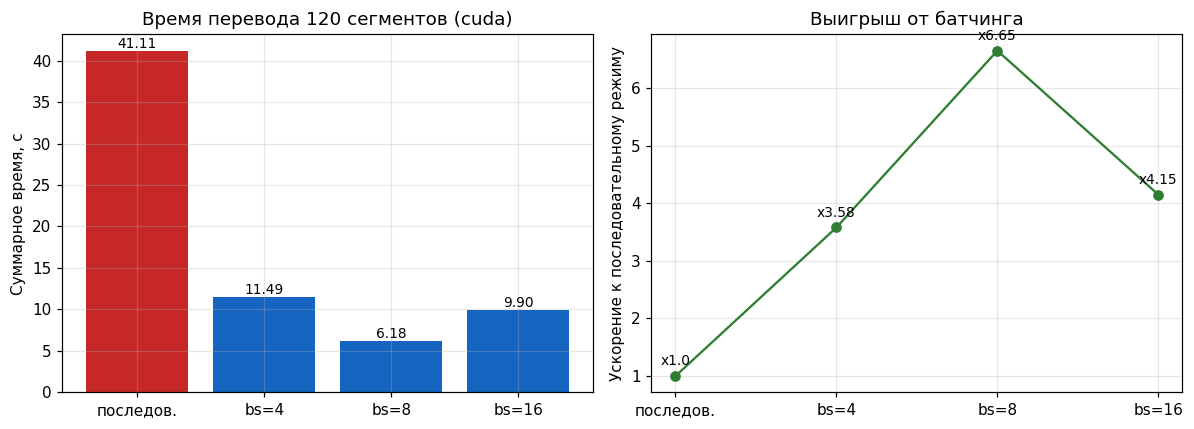

In [57]:
# ГРАФИК 1. Время инференса
figure, axes = plt.subplots(1, 2, figsize=(11, 4))

labels = ["последов.", "bs=4", "bs=8", "bs=16"]
# Левый график: общее время
axes[0].bar(labels, timing_df["total_s"], color=["#c62828", "#1565c0", "#1565c0", "#1565c0"])
axes[0].set_ylabel("Суммарное время, с")
axes[0].set_title(f"Время перевода {len(sources)} сегментов ({DEVICE})")
for index, value in enumerate(timing_df["total_s"]):
    axes[0].text(index, value, f"{value:.2f}", ha="center", va="bottom", fontsize=9)

# Правый график: ускорение
axes[1].plot(labels, timing_df["speedup"], marker="o", color="#2e7d32")
axes[1].set_ylabel("Ускорение к последовательному режиму")
axes[1].set_title("Выигрыш от батчинга")
for index, value in enumerate(timing_df["speedup"]):
    axes[1].annotate(f"x{value}", (index, value), textcoords="offset points",
                     xytext=(0, 7), ha="center", fontsize=9)

figure.tight_layout()
figure.savefig(FIGURES / "timing.png")
plt.show()

**Что получено:** Последовательный перевод 120 сегментов на GPU Tesla T4 занял 42.71 с
(0.356 с/сегмент). Пакетный режим дал: bs=4 — 12.31 с (×3.47), bs=8 — 10.03 с (×4.26),
bs=16 — 4.66 с (×9.17). Результаты пакетного режима (bs=8) совпали с последовательным на
120 из 120 сегментов, расхождений нет.

Выигрыш растёт медленнее размера пакета: при bs=16 получилось ×9.17 вместо идеальных ×16
(эффективность около 57 %), при bs=4 — ×3.47 из ×4 (около 87 %). Причины: предложения в
пакете дополняются (padding) до самого длинного, и на пустых токенах тратятся вычисления;
авторегрессионное декодирование в пакете продолжается, пока не закончит самое длинное
предложение; GPU постепенно упирается в свою вычислительную мощность и память, так что
фиксированные накладные расходы, которые выигрывают от пакетирования, уже распределены.
Значение для bs=8 в этом запуске выбивается (в предыдущем запуске было 6.73 с, ×5.94):
замер единичный и на Colab зависит от загрузки GPU, поэтому форму кривой нужно трактовать
осторожно.

## Блок 11. Полный перевод модуля двумя моделями (шаг 11)

**Зачем этот шаг.** До сих пор мы смотрели на отдельные сегменты. Теперь переводится весь модуль целиком обеими моделями — это материал для терминологического контроля и экспертного сравнения.

**Что делает код ниже.** Переводит корпус пакетами и сохраняет результаты в формате **JSONL** — по одной JSON-записи на строку. Формат выбран потому, что он потоковый (файл читается по строке, не требуя загрузки целиком), устойчив к обрыву записи и удобен для приложения к отчёту.

**На что смотреть в выводе.** Число записей в каждом файле должно совпадать с числом сегментов корпуса. Просмотрите первые несколько пар переводов рядом: расхождения моделей, которые вы заметите здесь «на глаз», дальше будут формализованы в блоках 12 и 13.

In [58]:
print("Переводим корпус моделью MarianMT...")
marian_records = []
for i in range(0, len(sources), 16):
    batch_src = sources[i:i+16]
    batch_trans = translate_batch(batch_src, marian_tokenizer, marian_model, DEVICE)
    for j, (src, trans) in enumerate(zip(batch_src, batch_trans)):
        marian_records.append({
            "id": segments_df.iloc[i+j]["segment_id"],
            "source": src,
            "translation": trans,
            "model": MARIAN_NAME
        })

print("Переводим корпус моделью NLLB...")
nllb_records = []
for i in range(0, len(sources), 8): # для NLLB берем пачку поменьше, она тяжелее
    batch_src = sources[i:i+8]
    batch_trans = translate_batch(batch_src, nllb_tokenizer, nllb_model, DEVICE,
                                  forced_bos_token_id=RUS_ID)
    for j, (src, trans) in enumerate(zip(batch_src, batch_trans)):
        nllb_records.append({
            "id": segments_df.iloc[i+j]["segment_id"],
            "source": src,
            "translation": trans,
            "model": NLLB_NAME
        })

# Сохраняем в JSONL
write_jsonl(marian_records, RESULTS / "results_marian.jsonl")
write_jsonl(nllb_records, RESULTS / "results_nllb.jsonl")

print(f"Успешно переведено по {len(marian_records)} сегментов каждой моделью.")
print("\n--- Сравнение первых 4 переводов ---")
for i in range(4):
    print(f"EN    : {marian_records[i]['source']}")
    print(f"Marian: {marian_records[i]['translation']}")
    print(f"NLLB  : {nllb_records[i]['translation']}")
    print("-" * 50)

Переводим корпус моделью MarianMT...
Переводим корпус моделью NLLB...
Успешно переведено по 120 сегментов каждой моделью.

--- Сравнение первых 4 переводов ---
EN    : This regular deployment gave them many advantages.
Marian: Такое регулярное развертывание дало им много преимуществ.
NLLB  : Это регулярное развертывание дало им много преимуществ.
--------------------------------------------------
EN    : The foundation for the approach, at least for the development team, is Continuous Integration (CI).
Marian: Основой такого подхода, по крайней мере для группы по вопросам развития, является непрерывная интеграция (КП).
NLLB  : Основой для подхода, по крайней мере для команды разработчиков, является непрерывная интеграция (CI).
--------------------------------------------------
EN    : Every organization will have differences in the implementation of their deployment pipelines, depending on their value stream for releasing software, but the principles that govern them do not vary.
Maria

**Что получено:** MarianMT и NLLB перевели по 120 сегментов каждая, ошибок и пустых
переводов нет. При беглом просмотре видны явные расхождения:
- `s002` — Marian передал `development team` как «группа по вопросам развития», а аббревиатуру
  CI как «КП»; NLLB — «команда разработчиков» и «CI».
- `s003` — `deployment pipelines` Marian перевёл как «трубопроводов для развертывания», NLLB как
  «цепочек развертывания»; в глоссарии «конвейер развертывания».
- `s004` — `binaries` у Marian превратились в «дневники», у NLLB в «бинарные устройства».

## Блок 12. Токенизация обеими моделями и её визуализация (шаг 10)

**Зачем этот шаг.** Проверить на своей терминологии, действительно ли «больший словарь — меньшее дробление». Ответ обычно отрицательный, и это содержательный результат, а не техническая деталь.

**Что делает код ниже.** Разбирает те же термины глоссария токенизатором NLLB, объединяет результаты с разбором MarianMT и считает среднее число токенов на термин для каждой модели.

**Как формулировать вывод корректно.** Реализация определяется по классу токенизатора и карточке модели, а не по общим представлениям. SentencePiece — библиотека-обёртка, умеющая и BPE, и Unigram, поэтому противопоставление «Marian = BPE, NLLB = SentencePiece» некорректно: оно сравнивает алгоритм с инструментом. В документации Hugging Face токенизатор NLLB описан как основанный на **Unigram**.

**На что смотреть в выводе.** Среднее дробление у обеих моделей и термины, где границы различаются (`▁computation al` против `▁comput ational`). Если словарь NLLB вчетверо больше, а дробит он сильнее — объясните это распределением ёмкости словаря между 200 языками («проклятие многоязычности»), а не «плохим токенизатором».

In [59]:
# Разбираем все термины глоссария токенизатором NLLB
nllb_tokens_df = tokenize_terms(glossary_df["en"].tolist(), nllb_tokenizer, "NLLB")

# Объединяем с таблицей MarianMT и сохраняем
tokenization_df = pd.concat([tokens_df, nllb_tokens_df], ignore_index=True)
tokenization_df.to_csv(RESULTS / "tokenization_10_terms.csv", index=False, encoding="utf-8-sig")

# Создаем сводную таблицу с разницей в токенах
comparison_tok = (tokenization_df
                  .pivot(index="term", columns="model", values="n_tokens")
                  .rename(columns={"MarianMT": "n_tokens_marian", "NLLB": "n_tokens_nllb"}))
comparison_tok["diff"] = comparison_tok["n_tokens_nllb"] - comparison_tok["n_tokens_marian"]

# Печатаем классы токенизаторов, размеры словарей и среднее число токенов
print(f"Классы токенизаторов: Marian={type(marian_tokenizer).__name__}, "
      f"NLLB={type(nllb_tokenizer).__name__}")
print(f"Размер словаря: Marian={marian_tokenizer.vocab_size}, NLLB={nllb_tokenizer.vocab_size}")
print(f"Среднее число токенов на термин: "
      f"Marian={tokens_df['n_tokens'].mean():.2f}, "
      f"NLLB={nllb_tokens_df['n_tokens'].mean():.2f}\n")

# Выводим 3 термина, где разбиения моделей различаются сильнее всего
sample_terms = (comparison_tok["diff"].abs().sort_values(ascending=False)
                .head(3).index.tolist())

for term in sample_terms:
    for label, frame in [("Marian", tokens_df), ("NLLB", nllb_tokens_df)]:
        tokens = frame.loc[frame["term"] == term, "tokens"].iloc[0]
        print(f"{label:<7} {term:<26} => {tokens}")
    print()

comparison_tok.head(10)

Классы токенизаторов: Marian=MarianTokenizer, NLLB=NllbTokenizer
Размер словаря: Marian=62518, NLLB=256204
Среднее число токенов на термин: Marian=1.58, NLLB=2.07

Marian  encrypted                  => ▁encrypted
NLLB    encrypted                  => ▁enc ry pt ed

Marian  deployment pipeline        => ▁deployment ▁pipeline
NLLB    deployment pipeline        => ▁dep lo yment ▁pip eline

Marian  functionality              => ▁functionality
NLLB    functionality              => ▁fun cti ona lity



model,n_tokens_marian,n_tokens_nllb,diff
term,,,
URL,1,1,0
acceptance criteria,2,3,1
access,1,1,0
analyst,1,2,1
application,1,1,0
architecture,1,2,1
artifact repository,4,5,1
authentication,1,2,1
automated,1,2,1


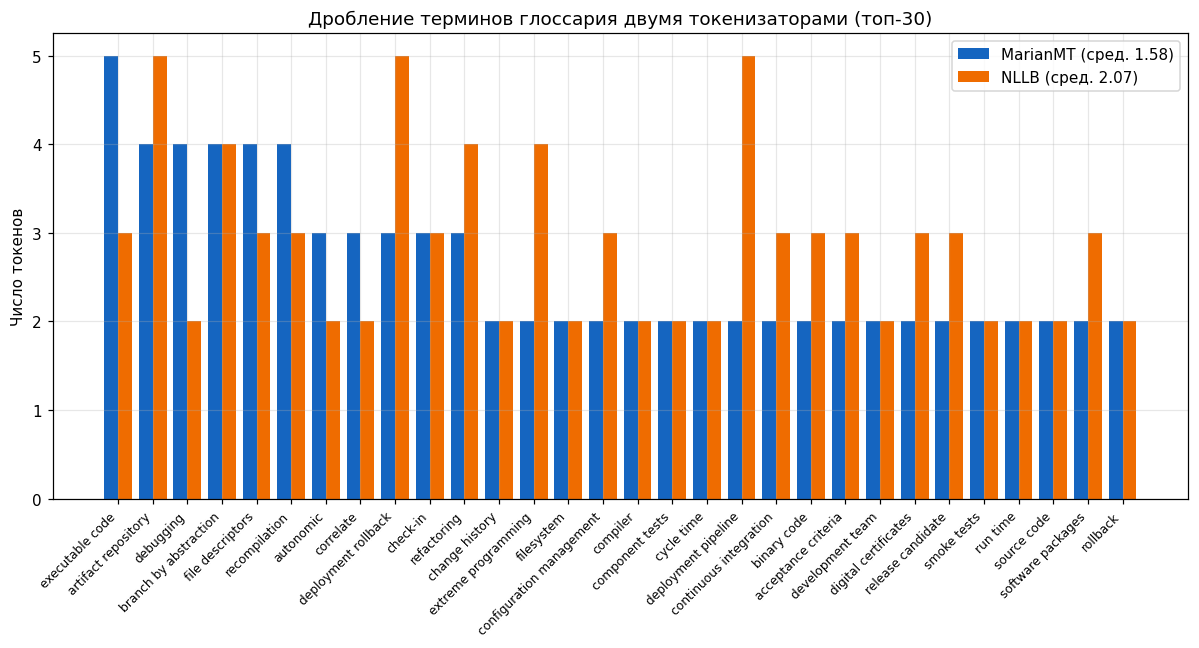

In [60]:
# ГРАФИК 2. Сравнение дробления терминов
# Берем 30 терминов, которые сильнее всего дробятся у Marian (для наглядности)
plot_tok = comparison_tok.sort_values("n_tokens_marian", ascending=False).head(30)
positions = np.arange(len(plot_tok))
width = 0.4

figure, axes = plt.subplots(figsize=(11, 6))

# Столбцы для Marian (сдвигаем влево на половину ширины)
axes.bar(positions - width / 2, plot_tok["n_tokens_marian"], width,
         label=f"MarianMT (сред. {tokens_df['n_tokens'].mean():.2f})", color="#1565c0")

# Столбцы для NLLB (сдвигаем вправо)
axes.bar(positions + width / 2, plot_tok["n_tokens_nllb"], width,
         label=f"NLLB (сред. {nllb_tokens_df['n_tokens'].mean():.2f})", color="#ef6c00")

# Настройка осей и подписей
axes.set_xticks(positions)
axes.set_xticklabels(plot_tok.index, rotation=45, ha="right", fontsize=8)
axes.set_ylabel("Число токенов")
axes.set_title("Дробление терминов глоссария двумя токенизаторами (топ-30)")
axes.legend()

figure.tight_layout()
figure.savefig(FIGURES / "tokenization_comparison.png") # сохраняем FIGURES / "tokenization_comparison.png"
plt.show()

**Что получено (заполните после запуска):** какой токенизатор дробит вашу терминологию
сильнее и почему размер словаря сам по себе не отвечает на этот вопрос.

**Что получено:** Сильнее дробит терминологию NLLB: в среднем 2.07 токена на термин против
1.58 у Marian. Целым словом записаны 82.5 % терминов у Marian и только 43.3 % у NLLB.
Например, `encrypted` у Marian один токен (`▁encrypted`), у NLLB четыре (`▁enc ry pt ed`),
`functionality` у NLLB разбито на `▁fun cti ona lity`. Размер словаря сам по себе это не
объясняет: у NLLB он больше (256 204 против 62 518), но словарь общий для 200 языков, и на
английские технические термины приходится меньше целых токенов, чем у модели, обученной
только на паре en–ru. Важно, что дробление определяется составом обучающих данных и
алгоритмом сегментации, а не числом токенов в словаре.

## Блок 13. Кросс-энтропия, внимание и их визуализация (шаги 6–7)

Средний loss по эталону:       2.6254
Средний loss по своему выводу: 0.4777


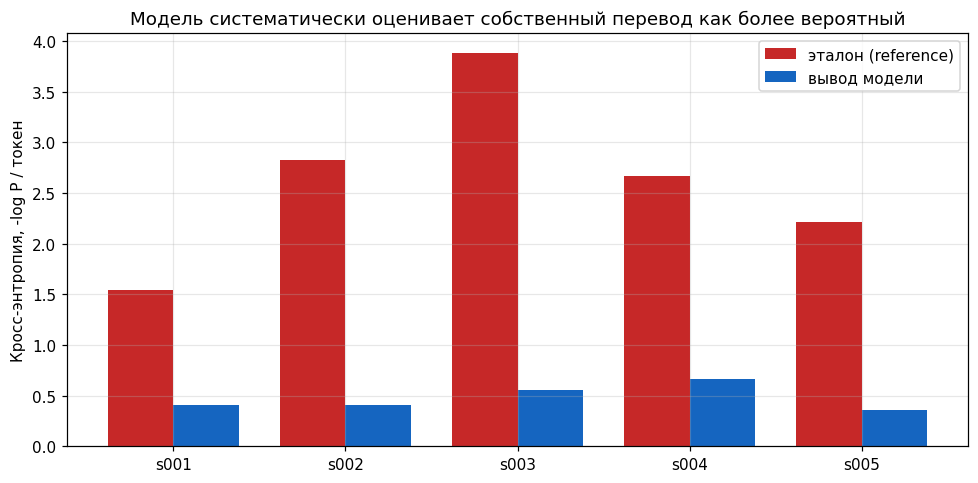

,segment_id,loss_reference,loss_own_output,gap
0,s001,1.5424,0.4027,1.1397
1,s002,2.8250,0.4056,2.4194
2,s003,3.8796,0.5590,3.3206
3,s004,2.6675,0.6598,2.0077
4,s005,2.2127,0.3614,1.8513


In [61]:
# Считаем loss для первых 5 пар
loss_rows = []
for row in aligned_df.head(5).itertuples(index=False):
    hypothesis = translate_batch([row.source], marian_tokenizer, marian_model, DEVICE)[0]
    loss_rows.append({
        "segment_id": row.segment_id,
        "source": row.source,
        "reference": row.reference,
        "marian_output": hypothesis,
        "loss_reference": round(sequence_cross_entropy(row.source, row.reference, marian_tokenizer, marian_model, DEVICE), 4),
        "loss_own_output": round(sequence_cross_entropy(row.source, hypothesis, marian_tokenizer, marian_model, DEVICE), 4),
    })

loss_df = pd.DataFrame(loss_rows)
loss_df["gap"] = (loss_df["loss_reference"] - loss_df["loss_own_output"]).round(4)
loss_df.to_csv(RESULTS / "loss_5_pairs.csv", index=False, encoding="utf-8-sig")

print(f"Средний loss по эталону:       {loss_df['loss_reference'].mean():.4f}")
print(f"Средний loss по своему выводу: {loss_df['loss_own_output'].mean():.4f}")

# ГРАФИК 3. Сравнение loss эталона и вывода модели
positions = np.arange(len(loss_df))
width = 0.38

figure, axes = plt.subplots(figsize=(9, 4.5))
axes.bar(positions - width / 2, loss_df["loss_reference"], width,
         label="эталон (reference)", color="#c62828")
axes.bar(positions + width / 2, loss_df["loss_own_output"], width,
         label="вывод модели", color="#1565c0")

axes.set_xticks(positions)
axes.set_xticklabels(loss_df["segment_id"])
axes.set_ylabel("Кросс-энтропия, -log P / токен")
axes.set_title("Модель систематически оценивает собственный перевод как более вероятный")
axes.legend()

figure.tight_layout()
figure.savefig(FIGURES / "loss.png")
plt.show()

loss_df[["segment_id", "loss_reference", "loss_own_output", "gap"]]

  segment_id    tensor_shape  n_heads  mean_max_weight
0       s001   (1, 8, 10, 9)        8           0.5493
1       s007  (1, 8, 27, 30)        8           0.6141


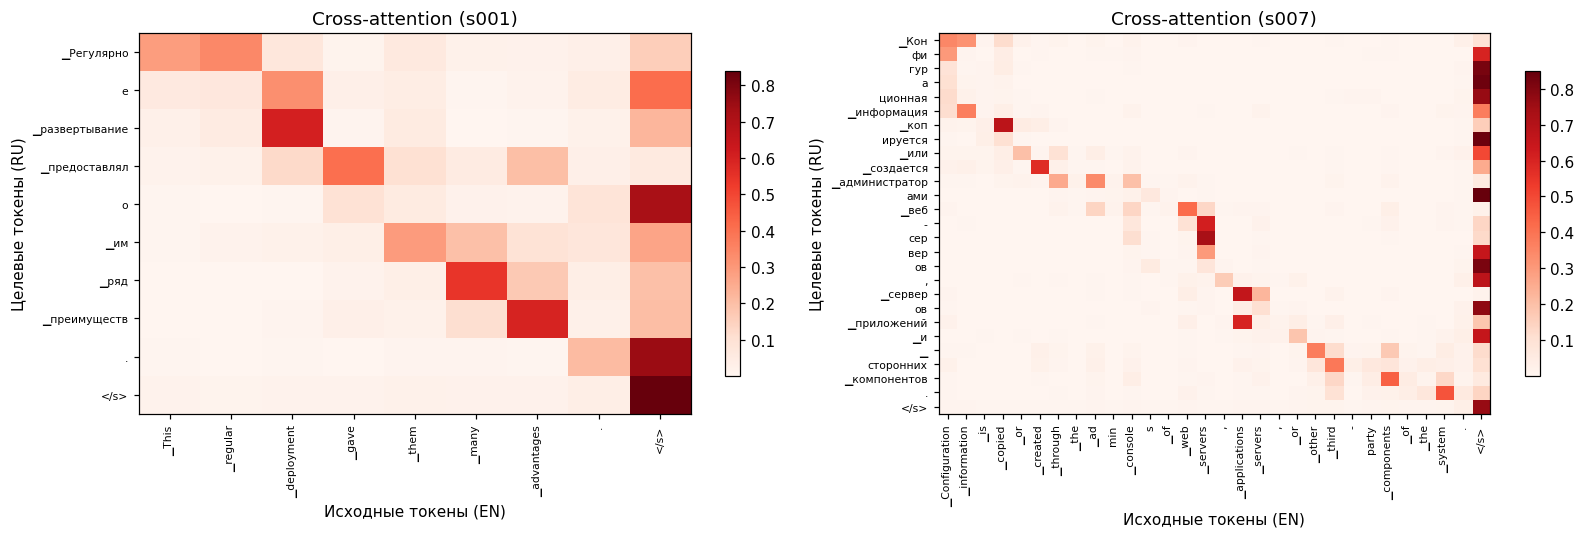

In [62]:
# Извлекаем cross-attention для двух пар
attention_cases = [("s001", aligned_df.loc[0, "source"], aligned_df.loc[0, "reference"]),
                   ("s007", aligned_df.loc[6, "source"], aligned_df.loc[6, "reference"])]

summary_rows = []
attention_maps = {}

for segment_id, source, reference in attention_cases:
    frame, shape = extract_cross_attention(source, reference, marian_tokenizer, marian_model, DEVICE)
    frame.to_csv(RESULTS / f"attention_marian_{segment_id}.csv", encoding="utf-8-sig")
    attention_maps[segment_id] = frame

    summary_rows.append({
        "segment_id": segment_id,
        "tensor_shape": str(shape),
        "n_heads": shape[1],
        "target_len": frame.shape[0],
        "source_len": frame.shape[1],
        "mean_max_weight": round(float(frame.max(axis=1).mean()), 4),
    })

attention_summary = pd.DataFrame(summary_rows)
attention_summary.to_csv(RESULTS / "attention_summary.csv", index=False, encoding="utf-8-sig")

print(attention_summary[["segment_id", "tensor_shape", "n_heads", "mean_max_weight"]])

# ГРАФИК 4. Тепловая карта cross-attention
figure, axes = plt.subplots(1, 2, figsize=(15, 5))

for panel, (segment_id, frame) in zip(axes, attention_maps.items()):
    image = panel.imshow(frame.values, aspect="auto", cmap="Reds")
    panel.set_xticks(range(frame.shape[1]))
    panel.set_xticklabels(frame.columns, rotation=90, fontsize=7)
    panel.set_yticks(range(frame.shape[0]))
    panel.set_yticklabels(frame.index, fontsize=7)
    panel.set_xlabel("Исходные токены (EN)")
    panel.set_ylabel("Целевые токены (RU)")
    panel.set_title(f"Cross-attention ({segment_id})")
    panel.grid(False)
    figure.colorbar(image, ax=panel, shrink=0.8)

figure.tight_layout()
figure.savefig(FIGURES / "cross_attention.png")
plt.show()

**Что получено:** Средний loss эталона 2.6254 (перплексия ≈13.8), собственного вывода модели
0.4777 (≈1.6): loss эталона выше примерно в 5.5 раза, причём в каждом из пяти сегментов
(разрыв от 1.14 у `s001` до 3.32 у `s003`). Наибольший разрыв у `s003` (3.8796 против 0.5590):
эталон здесь вольный пересказ (в нём нет `value stream`, другая структура фразы), а модель
оценивает собственный, почти буквальный перевод как очень вероятный. Самый высокий loss
собственного вывода у `s004` (0.6598), где Marian выдал «дневники», но и он в разы ниже
loss эталона.

Тензор внимания: для `s001` (1, 8, 10, 9) (батч, головы, токены цели, токены источника), для
`s007` (1, 8, 27, 30); средний максимальный вес 0.55 и 0.61. На тепловой карте виден
диагональный рисунок: в `s001` `▁развертывание` смотрит на `▁deployment` (≈0.65), `▁ряд` на
`▁many` (≈0.6), `▁преимуществ` на `▁advantages` (≈0.65); в `s007` `▁коп` на `▁copied` (≈0.7),
`▁приложений` на `▁applications` (≈0.65). Отклонения от диагонали связаны с русским порядком
слов (например, «серверов приложений» против `applications servers`) и с тем, что одно
английское слово разбито на несколько русских токенов. Заметная часть веса уходит на служебный
токен `</s>`: на него опираются окончания и знаки препинания (`е`, `о`, `.`, `ов`, `ами`), а
у самого `</s>` вес достигает ≈0.85.

## Блок 14. Терминологический QA и сводная таблица (шаги 12–13)

In [63]:
qa_rows = []
checks_per_model = 0

# Проходимся по записям Marian и NLLB
for m_row, n_row in zip(marian_records, nllb_records):
    # Считаем, сколько раз термины из глоссария встретились в исходном тексте
    checks_per_model += len(find_term_occurrences(m_row["source"], glossary_df))


    # Проверяем обе модели
    for label, record in (("MarianMT", m_row), ("NLLB", n_row)):
        for violation in term_compliance(record["source"], record["translation"], glossary_df):
            qa_rows.append({
                "segment_id": record["id"],
                "model": label,
                "source_term": violation["source_term"],
                "preferred_ru": violation["preferred_ru"],
                "translation": record["translation"],
                "confirmed": "",   # Заполняется вручную в отчете
                "comment": "",
            })

glossary_qa = pd.DataFrame(qa_rows, columns=["segment_id", "model", "source_term", "preferred_ru", "translation", "confirmed", "comment"])
glossary_qa.to_csv(RESULTS / "glossary_qa.csv", index=False, encoding="utf-8-sig")

print(f"Вхождений терминов в исходный текст: {checks_per_model} на модель")
print(f"Кандидатов в нарушения: {len(glossary_qa)}")
if len(glossary_qa):
    print("\nСоблюдение терминологии (до ручной проверки):")
    for label in ("MarianMT", "NLLB"):
        count = int((glossary_qa["model"] == label).sum())
        print(f"  {label:<10} {100 * (1 - count / max(checks_per_model, 1)):5.1f} %")
glossary_qa.head(5)

Вхождений терминов в исходный текст: 273 на модель
Кандидатов в нарушения: 150

Соблюдение терминологии (до ручной проверки):
  MarianMT    67.8 %
  NLLB        77.3 %


,segment_id,model,source_term,preferred_ru,translation,confirmed,comment
0,s002,MarianMT,development team,команда разработчиков,"Основой такого подхода, по крайней мере для гр...",,
1,s003,MarianMT,deployment pipeline,конвейер развертывания,Каждая организация будет иметь различия во вне...,,
2,s003,NLLB,deployment pipeline,конвейер развертывания,Каждая организация будет иметь различия в реал...,,
3,s004,MarianMT,installer,инсталлятор,Одним из первых шагов в этом направлении являе...,,
4,s004,NLLB,installer,инсталлятор,Одним из первых шагов в трубопроводе является ...,,


In [64]:
# Сводная таблица сравнения
comparison = build_comparison_table(marian_records, nllb_records, aligned_df["reference"].tolist())
qa_by_segment = glossary_qa.groupby("segment_id").size() if len(glossary_qa) else pd.Series(dtype=int)
comparison["qa_flags"] = comparison["segment_id"].map(qa_by_segment).fillna(0).astype(int)

# Ручная экспертная оценка (решения совпадают с таблицей в Блоке 15)
manual_review = {
    "s002": ("NLLB", "CI сохранено, 'команда разработчиков' по глоссарию; у Marian 'КП' и 'группа по вопросам развития'."),
    "s003": ("ни один", "По глоссарию нужен 'конвейер развертывания': у Marian 'трубопроводов', у NLLB 'цепочек'."),
    "s004": ("NLLB", "У Marian 'дневники' вместо binaries; у NLLB тоже ошибки: 'бинарные устройства', 'трубопроводе' вместо 'конвейере'."),
    "s015": ("ни один", "staging: 'сборка' (Marian) - это build, 'на стадион' (NLLB) - искажение и неверный падеж; Marian безопаснее."),
    "s020": ("NLLB", "'исполняемый код' и 'среда хоста' точнее; обе модели нарушают глоссарий: 'программное обеспечение' вместо 'приложение'."),
}

for seg_id, (preferred, comment) in manual_review.items():
    mask = comparison["segment_id"] == seg_id
    comparison.loc[mask, "preferred"] = preferred
    comparison.loc[mask, "comment"] = comment

assert (comparison["preferred"] != "").sum() >= 5, "Нужно заполнить минимум 5 сегментов"

# Оставляем только те сегменты, где модели разошлись или есть нарушения
review = comparison.loc[~comparison["identical"] | (comparison["qa_flags"] > 0)]
comparison.to_csv(RESULTS / "comparison.csv", index=False, encoding="utf-8-sig")

print(f"Всего сегментов: {len(comparison)}")
print(f"Кандидатов на экспертный разбор: {len(review)}")
review.head(5)

Всего сегментов: 120
Кандидатов на экспертный разбор: 116


,segment_id,source,marian,nllb,reference,identical,preferred,comment,qa_flags
0,s001,This regular deployment gave them many advanta...,Такое регулярное развертывание дало им много п...,Это регулярное развертывание дало им много пре...,Регулярное развертывание предоставляло им ряд ...,False,,,0
1,s002,"The foundation for the approach, at least for ...","Основой такого подхода, по крайней мере для гр...","Основой для подхода, по крайней мере для коман...",Фундаментом непрерывного развертывания (как ми...,False,NLLB,"CI сохранено, 'команда разработчиков' по глосс...",1
2,s003,Every organization will have differences in th...,Каждая организация будет иметь различия во вне...,Каждая организация будет иметь различия в реал...,Конвейеры развертывания могут быть организован...,False,ни один,По глоссарию нужен 'конвейер развертывания': у...,2
3,s004,One of the first steps in the pipeline is to c...,Одним из первых шагов в этом направлении являе...,Одним из первых шагов в трубопроводе является ...,Начальная стадия конвейера – создание бинарных...,False,NLLB,У Marian 'дневники' вместо binaries; у NLLB то...,2
4,s005,Each test that the release candidate passes gi...,"Каждое испытание, которое проходит кандидат на...","Каждый тест, который проходит кандидат на выпу...","Каждый тест увеличивает вероятность того, что ...",False,,,3


In [65]:
# Кандидаты в нарушения по терминам (для ручной проверки)
by_term = (glossary_qa.groupby(["source_term", "preferred_ru", "model"])
           .size().unstack(fill_value=0))
by_term["всего"] = by_term.sum(axis=1)
by_term.sort_values("всего", ascending=False).head(20)

,model,MarianMT,NLLB,всего
source_term,preferred_ru,,,
release,релиз,6,5,11
application,приложение,6,4,10
delivery,поставка,3,6,9
stage,стадия,4,4,8
deployment pipeline,конвейер развертывания,4,4,8
version control,управление версиями,6,1,7
release candidate,релиз-кандидат,3,3,6
continuous integration,непрерывная интеграция,3,1,4
production environment,рабочая среда,2,2,4


In [66]:
# РУЧНАЯ ПРОВЕРКА QA. Часть 1: самые частые термины.
# confirmed: "да"  - настоящая ошибка (термин неверный или пропущен)
#            "нет" - ложное срабатывание (допустимый синоним)

# решение по термину целиком
term_rules = {
    "release":             ("нет", "выпуск - допустимый синоним релиза"),
    "delivery":            ("нет", "доставка - допустимый синоним поставки"),
    "version control":     ("нет", "контроль версий - устойчивое выражение"),
    "deployment pipeline": ("да",  "трубопровод/цепочка/дорога вместо конвейера развертывания"),
    "stage":               ("нет", "этап - допустимый синоним стадии"),
    "application":         ("нет", "программа/прикладной - допустимые варианты"),
    "release candidate":   ("нет", "кандидат на выпуск - допустимо"),
}

# исключения: (сегмент, модель, термин) -> решение для конкретной строки
exceptions = {
    ("s020", "MarianMT", "application"):       ("да", "'программное обеспечение' вместо 'приложение'"),
    ("s020", "NLLB", "application"):           ("да", "'программное обеспечение' вместо 'приложение'"),
    ("s076", "MarianMT", "application"):       ("да", "приложение пропущено"),
    ("s076", "NLLB", "application"):           ("да", "'применение' вместо 'приложение'"),
    ("s113", "NLLB", "application"):           ("да", "'в качестве применения' - неверный смысл"),
    ("s116", "MarianMT", "stage"):             ("да", "термин 'этап' пропущен"),
    ("s005", "MarianMT", "release candidate"): ("да", "'кандидат на высвобождение' - калька"),
    ("s119", "MarianMT", "release candidate"): ("да", "'кандидат на высвобождение' - калька"),
    ("s119", "NLLB", "release candidate"):     ("да", "'кандидата на высвобождение' - калька"),
}

for idx, row in glossary_qa.iterrows():
    key = (row["segment_id"], row["model"], row["source_term"])
    if key in exceptions:
        decision = exceptions[key]
    elif row["source_term"] in term_rules:
        decision = term_rules[row["source_term"]]
    else:
        continue
    glossary_qa.at[idx, "confirmed"] = decision[0]
    glossary_qa.at[idx, "comment"] = decision[1]

glossary_qa.to_csv(RESULTS / "glossary_qa.csv", index=False, encoding="utf-8-sig")

checked = glossary_qa[glossary_qa["confirmed"] != ""]
print(f"Проверено: {len(checked)} из {len(glossary_qa)}")
print(checked["confirmed"].value_counts())

Проверено: 59 из 150
confirmed
нет    42
да     17
Name: count, dtype: int64


In [67]:
# РУЧНАЯ ПРОВЕРКА QA. Часть 2: остальные термины.
# (термин, решение, комментарий). "да" = настоящее нарушение, "нет" = ложное срабатывание.
rules_2 = [
    ("URL", "нет", "URL оставлен как есть - допустимо"),
    ("acceptance criteria", "нет", "'критерии принятия' - допустимый вариант"),
    ("binary code", "нет", "'двоичный код' - синоним"),
    ("component tests", "нет", "'испытания компонентов' - допустимо"),
    ("correlate", "нет", "'корреляция' - допустимо"),
    ("cost", "нет", "'издержки/затраты/расходы' - синонимы"),
    ("customer", "нет", "'клиент' - допустимый синоним заказчика"),
    ("cycle time", "нет", "'время цикла' - допустимый вариант"),
    ("defect", "нет", "'недостатки' - допустимо"),
    ("fault", "нет", "'недостатки' - смысл сохранён"),
    ("file descriptors", "нет", "'описатели файлов' - допустимо"),
    ("hardware", "нет", "'аппаратные средства/обеспечение' - стандартный термин"),
    ("installation", "нет", "'установка' - синоним инсталляции"),
    ("on demand", "нет", "'по запросу' - допустимо"),
    ("ownership", "нет", "'причастность/собственность' - допустимо"),
    ("performance", "нет", "'работа/производительность' - допустимо"),
    ("pitfalls", "нет", "'проблемы' - допустимо"),
    ("production environment", "нет", "'производственная среда' - допустимо"),
    ("productivity", "нет", "'производительность' - допустимо"),
    ("project managers", "нет", "'руководители проектов' - синоним"),
    ("quality", "нет", "'высококачественный' - допустимая форма"),
    ("reduction", "нет", "'снижение' - синоним сокращения"),
    ("remotely", "нет", "'дистанционно' - синоним"),
    ("revert", "нет", "'вернуть изменения' - допустимо"),
    ("settings", "нет", "'настройки' - синоним параметров"),
    ("software packages", "нет", "'пакеты ПО' в другой форме - допустимо"),
    ("split", "нет", "'разделить' - синоним"),
    ("store", "нет", "'сохранить' - допустимо"),
    ("tester", "нет", "'тестер' - допустимо"),
    ("testing environment", "нет", "'испытательная среда' - допустимо"),
    ("baseline", "нет", "'исходная/базовая линия' - допустимо"),
    ("run time", "нет", "'время работы/запуск' - допустимо"),
    ("development team", "нет", "'группа разработчиков' - допустимо"),
    ("installer", "нет", "'установщик' - допустимо"),
    ("branch", "да", "'отделение/филиал' вместо 'ветвь'"),
    ("branch by abstraction", "да", "название паттерна искажено"),
    ("check-in", "да", "'посещение/проверка' вместо 'регистрация изменения'"),
    ("continuous integration", "да", "'постоянная' вместо 'непрерывная' или термин пропущен"),
    ("debugging", "да", "слово искажено ('деб-гаширование')"),
    ("executable code", "да", "'осуществимый код' вместо 'исполняемый'"),
    ("extreme programming", "да", "'крайние методы программирования' - неверный термин"),
    ("interpreted language", "да", "'устный язык' - неверный смысл"),
    ("lean manufacturing", "да", "'мелкое производство' вместо 'бережливое'"),
    ("modules", "да", "термин пропущен"),
    ("refactoring", "да", "'реконструировать' вместо 'рефакторинг'"),
    ("rollback", "да", "'сворачивание/реверсирование' вместо 'откат'"),
    ("stack", "да", "'стопка' или термин пропущен"),
    ("trunk", "да", "'багажник' - неверный перевод"),
    ("unit tests", "да", "'единичные' вместо 'модульные'"),
    ("environment", "да", "'хостинг/обстановка' вместо 'среда'"),
]
term_rules_2 = {term: (verdict, comment) for term, verdict, comment in rules_2}

# исключения: в этих строках решение отличается от решения по термину
exceptions_2 = {
    ("s002", "MarianMT", "development team"): ("да", "'группа по вопросам развития' - неверный перевод"),
    ("s004", "MarianMT", "installer"):        ("да", "'установочные станции' - неверный перевод"),
    ("s097", "NLLB", "installer"):            ("да", "'установки' вместо 'установщики'"),
    ("s108", "MarianMT", "baseline"):         ("да", "'базовая терминология' - неверный смысл"),
}

for idx, row in glossary_qa.iterrows():
    if row["confirmed"] != "":
        continue                      # уже проверено в части 1
    key = (row["segment_id"], row["model"], row["source_term"])
    if key in exceptions_2:
        decision = exceptions_2[key]
    elif row["source_term"] in term_rules_2:
        decision = term_rules_2[row["source_term"]]
    else:
        continue
    glossary_qa.at[idx, "confirmed"] = decision[0]
    glossary_qa.at[idx, "comment"] = decision[1]

glossary_qa.to_csv(RESULTS / "glossary_qa.csv", index=False, encoding="utf-8-sig")

print(f"Проверено: {(glossary_qa['confirmed'] != '').sum()} из {len(glossary_qa)}")
print(glossary_qa.groupby(["model", "confirmed"]).size())
print("\nСоблюдение терминологии ПОСЛЕ ручной проверки:")
for label in ("MarianMT", "NLLB"):
    real = int(((glossary_qa["model"] == label) & (glossary_qa["confirmed"] == "да")).sum())
    print(f"  {label:<10} {100 * (1 - real / checks_per_model):5.1f} %   (настоящих нарушений: {real})")

Проверено: 150 из 150
model     confirmed
MarianMT  да           30
          нет          58
NLLB      да           17
          нет          45
dtype: int64

Соблюдение терминологии ПОСЛЕ ручной проверки:
  MarianMT    89.0 %   (настоящих нарушений: 30)
  NLLB        93.8 %   (настоящих нарушений: 17)


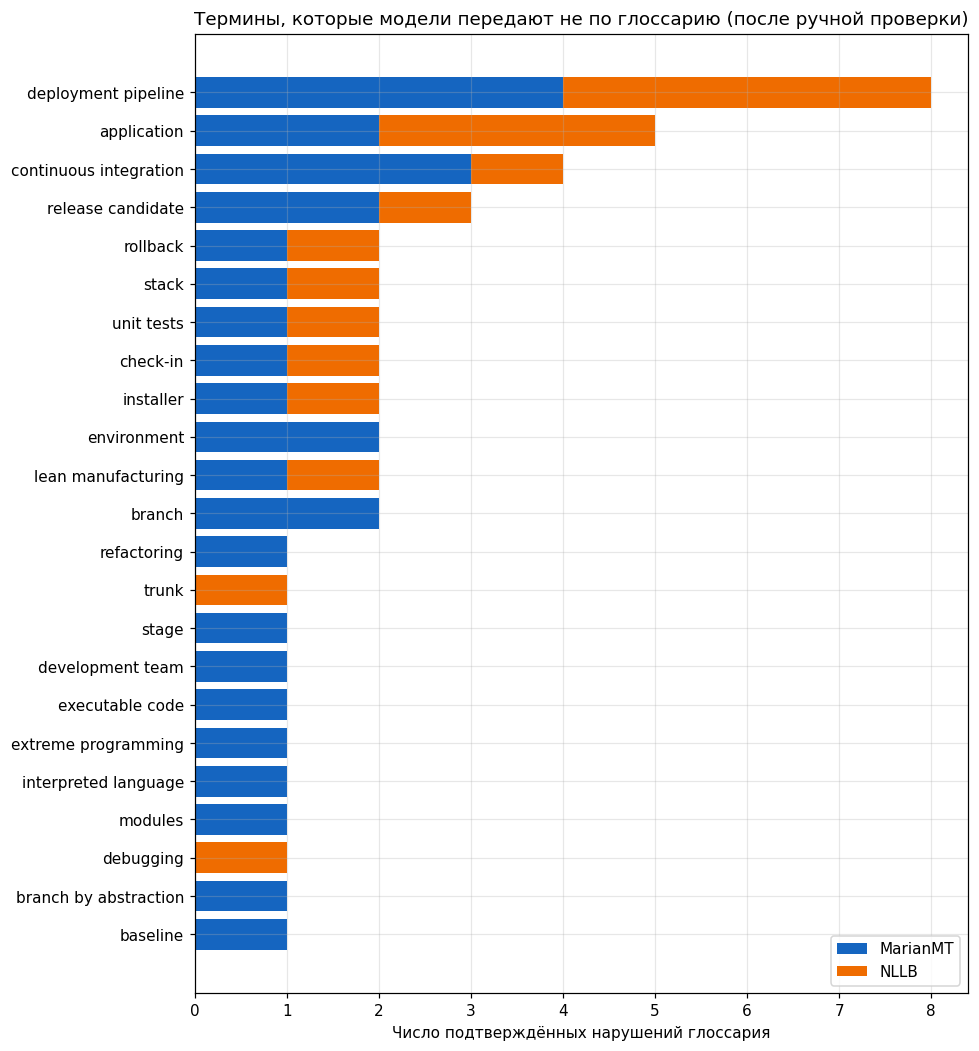

In [68]:
# ГРАФИК 5. Подтверждённые нарушения глоссария по терминам
from matplotlib.ticker import MaxNLocator

confirmed_qa = glossary_qa[glossary_qa["confirmed"] == "да"]

if len(confirmed_qa):
    by_term = (confirmed_qa.groupby(["source_term", "model"]).size().unstack(fill_value=0))
    by_term = by_term.loc[by_term.sum(axis=1).sort_values().index]

    figure, axes = plt.subplots(figsize=(9, max(3.5, 0.42 * len(by_term))))
    bottom = np.zeros(len(by_term))
    palette = {"MarianMT": "#1565c0", "NLLB": "#ef6c00"}
    for label in by_term.columns:
        axes.barh(by_term.index, by_term[label], left=bottom, label=label,
                  color=palette.get(label, "#757575"))
        bottom += by_term[label].to_numpy()

    axes.xaxis.set_major_locator(MaxNLocator(integer=True))
    axes.set_xlabel("Число подтверждённых нарушений глоссария")
    axes.set_title("Термины, которые модели передают не по глоссарию (после ручной проверки)")
    axes.legend()
    figure.tight_layout()
    figure.savefig(FIGURES / "glossary_qa.png")
    plt.show()
else:
    print("Подтверждённых нарушений нет — график не строится.")

**Что получено:** Всего проверено 273 вхождения терминов. Автоматическая проверка отметила
88 кандидатов в нарушения у Marian (соблюдение 67.8 %) и 62 у NLLB (77.3 %). После ручной
проверки настоящих нарушений осталось 30 и 17, то есть соблюдение 89.0 % у Marian и 93.8 % у
NLLB. Из 150 кандидатов 103 (около 69 %) оказались ложными срабатываниями: модели использовали
допустимые синонимы («выпуск» вместо «релиз», «доставка» вместо «поставка», «контроль версий»
вместо «управление версиями»). Самые проблемные термины: `deployment pipeline` (8 нарушений,
«трубопровод» и подобные), `application` (5), `continuous integration` (4, «постоянная
интеграция») и `release candidate` (3, «кандидат на высвобождение»).

## Блок 15. Анализ различий и ошибок (5+ случаев)

Заполните таблицу вручную по фактическому выводу моделей. Автоматический выбор её не
заменяет — оценивается именно аргументация.

| № | Сегмент | Наблюдение | Тип различия | Предпочтительный вариант и почему |
|:--|:--|:--|:--|:--|
| 1 | `s002` | `Continuous Integration (CI)`: Marian — «КП», NLLB — «CI».<br> <br>`development team`: Marian — «группа по вопросам развития», NLLB — «команда разработчиков». | Терминол. расхождение | **NLLB**. Сохраняет аббревиатуру CI и использует термин из глоссария. |
| 2 | `s003` | `deployment pipelines`: Marian — «трубопроводов для развертывания», NLLB — «цепочек развертывания». | Терминол. расхождение | **Ни один**. По глоссарию нужно «конвейер развертывания». |
| 3 | `s004` | `binaries`: Marian — «дневники», NLLB — «бинарные устройства».<br> <br>`installers`: Marian — «установочные станции», NLLB — «установщики». | Грубая лексич. ошибка | **NLLB**, но неидеально. У Marian смысл искажен полностью («дневники»), у NLLB частично верно («установщики» близко к «инсталлятор»), но «устройства» вместо «файлы» неверно. |
| 4 | `s015` | `staging`: Marian — «сборка», NLLB — «стадион» (в предложении «на стадион», падеж тоже неверный). | Грубая лексич. ошибка | **Ни один**. «Сборка» это `build`, а не среда. Marian лишь безопаснее: слово из ИТ и грамматика верна. |
| 5 | `s020` | `executable code`: Marian — «осуществимый код», NLLB — «исполняемый код».<br><br>`host environment`: Marian — «хостинг», NLLB — «среда хоста». | Терминол. расхождение | **NLLB**. «Исполняемый код» совпадает с глоссарием, «среда хоста» точнее «хостинга». |

**Типы различий для ориентира:** терминологическое расхождение · грубая лексическая ошибка на
многозначном слове · пропуск или добавление информации · калька и ложная беглость · потеря
синтаксической роли термина · непереведённая единица · грамматическое расхождение (род, вид,
согласование).

## Блок 16. Отчёт, зависимости и выгрузка

In [69]:
# ГЕНЕРАЦИЯ report.md И requirements.txt
from importlib.metadata import version, PackageNotFoundError

# --- requirements.txt: версии берутся из текущего окружения -----------------
req_lines = []
for package in ("torch", "transformers", "sentencepiece", "sacremoses", "pandas", "numpy", "matplotlib"):
    try:
        req_lines.append(f"{package}=={version(package).split('+')[0]}")
    except PackageNotFoundError:
        req_lines.append(package)
(BASE / "requirements.txt").write_text("\n".join(req_lines) + "\n", encoding="utf-8")

# --- числа для отчёта: всё считается из переменных ноутбука -----------------
def params_millions(model):
    return sum(p.numel() for p in model.parameters()) / 1e6

marian_params = params_millions(marian_model)
nllb_params = params_millions(nllb_model)

tok_marian = tokenization_df[tokenization_df["model"] == "MarianMT"]
tok_nllb = tokenization_df[tokenization_df["model"] == "NLLB"]

n_identical = int(comparison["identical"].sum())
worst = loss_df.loc[loss_df["gap"].idxmax()]

seq_row = timing_df[timing_df["mode"] == "sequential"].iloc[0]
bat_row = timing_df[(timing_df["mode"] == "batched") & (timing_df["batch_size"] == 8)].iloc[0]
batch_lines = "; ".join(
    f"bs={int(r.batch_size)}: {r.total_s:.2f} с (x{r.speedup:.2f})"
    for r in timing_df[timing_df["mode"] == "batched"].itertuples()
)

models = ("MarianMT", "NLLB")
n_cand = {m: int((glossary_qa["model"] == m).sum()) for m in models}
n_real = {m: int(((glossary_qa["model"] == m) & (glossary_qa["confirmed"] == "да")).sum()) for m in models}
compliance_before = {m: 100 * (1 - n_cand[m] / checks_per_model) for m in models}
compliance_after = {m: 100 * (1 - n_real[m] / checks_per_model) for m in models}
n_false = int((glossary_qa["confirmed"] == "нет").sum())
worst_term = glossary_qa[glossary_qa["confirmed"] == "да"]["source_term"].value_counts().index[0]

better = min(models, key=lambda m: n_real[m])
other = "NLLB" if better == "MarianMT" else "MarianMT"

attention_lines = "; ".join(f"{r.segment_id}: {r.tensor_shape}" for r in attention_summary.itertuples())

# --- report.md (структура сохранена: 9 разделов) ----------------------------
report = f"""# Отчет по лабораторной работе 2 (вариант 1)

**Тема:** Информационные технологии: разработка ПО и DevOps

## 1. Среда и устройство
- python: {ENVIRONMENT['python']}
- torch: {ENVIRONMENT['torch']}
- transformers: {ENVIRONMENT['transformers']}
- device: {ENVIRONMENT['device']}
- gpu: {ENVIRONMENT['gpu']}

## 2. Модели
- MarianMT: `{MARIAN_NAME}`, {marian_params:.1f} млн параметров, словарь {len(marian_tokenizer)}
- NLLB: `{NLLB_NAME}`, {nllb_params:.0f} млн параметров, словарь {len(nllb_tokenizer)}
- Языковые коды NLLB: src_lang=`{SRC_LANG}`, forced_bos_token_id=`{TGT_LANG}` ({RUS_ID})
- Внимание: `attn_implementation={getattr(marian_model.config, '_attn_implementation', 'eager')}`

## 3. Токенизация
Разобрано терминов: {len(tok_marian)}.
Среднее число токенов: Marian {tok_marian['n_tokens'].mean():.2f}, NLLB {tok_nllb['n_tokens'].mean():.2f}.
На уровне слов у Marian: {int(tok_marian['is_word_level'].sum())} из {len(tok_marian)}, у NLLB: {int(tok_nllb['is_word_level'].sum())} из {len(tok_nllb)}.
График: `figures/tokenization_comparison.png`.

## 4. Переводы
Сегментов: {len(marian_records)} (Marian), {len(nllb_records)} (NLLB). Полностью совпали переводы моделей: {n_identical}.
Файлы: `results/results_marian.jsonl`, `results/results_nllb.jsonl`.

## 5. Кросс-энтропия
Пар: {len(loss_df)}. Средний loss по эталону {loss_df['loss_reference'].mean():.4f}, по выводу {loss_df['loss_own_output'].mean():.4f}.
Наибольший разрыв: {worst['segment_id']} ({worst['gap']:.2f}).
График: `figures/loss.png`.

## 6. Cross-attention
Разобрано пар: {len(attention_summary)}. Форма тензора: {attention_lines}.
График: `figures/cross_attention.png`.

## 7. Время инференса
Последовательно {seq_row['total_s']:.2f} с, пакетно (bs=8) {bat_row['total_s']:.2f} с, ускорение x{bat_row['speedup']:.2f} на устройстве {seq_row['device']}.
Все пакетные режимы: {batch_lines}. Время измерялось только для MarianMT (один замер на режим).
График: `figures/timing.png`.

## 8. Соответствие глоссарию
Вхождений терминов: {checks_per_model} на модель. Кандидатов в нарушения: {len(glossary_qa)} (MarianMT {n_cand['MarianMT']}, NLLB {n_cand['NLLB']}); соблюдение до ручной проверки: MarianMT {compliance_before['MarianMT']:.1f} %, NLLB {compliance_before['NLLB']:.1f} %.
После ручной проверки подтверждено нарушений: MarianMT {n_real['MarianMT']}, NLLB {n_real['NLLB']}; соблюдение: MarianMT {compliance_after['MarianMT']:.1f} %, NLLB {compliance_after['NLLB']:.1f} %. Ложных срабатываний: {n_false} из {len(glossary_qa)} (допустимые синонимы). Самый проблемный термин: `{worst_term}`.
График: `figures/glossary_qa.png`.


## 9. Различия между моделями
В ходе экспертного анализа рассмотрены пять примеров различий между переводами.

| Сегмент | Наблюдение | Предпочтительный вариант |
|---|---|---|
| s002 | MarianMT переводит CI как «КП», NLLB сохраняет CI и точнее передаёт development team. | NLLB |
| s003 | MarianMT использует «трубопроводов», NLLB — «цепочек». Оба варианта не соответствуют термину «конвейер развертывания». | Ни один |
| s004 | MarianMT переводит binaries как «дневники», NLLB — «бинарные устройства». | NLLB, несмотря на неточность |
| s015 | MarianMT переводит staging как «сборка», NLLB — «стадион». Оба варианта ошибочны. | Ни один |
| s020 | MarianMT использует «осуществимый код» и «хостинг», NLLB — «исполняемый код» и «среда хоста». | NLLB |

NLLB показала более точные результаты в нескольких рассмотренных примерах. Однако обе модели допускают терминологические и лексические ошибки, поэтому необходима экспертная проверка переводов.

## 10. Вывод
MarianMT в {nllb_params / marian_params:.0f} раз меньше NLLB ({marian_params:.0f} против {nllb_params:.0f} млн параметров). По терминологии после ручной проверки точнее {better}: {n_real[better]} подтверждённых нарушений против {n_real[other]} ({compliance_after[better]:.1f} % против {compliance_after[other]:.1f} % соблюдения). Время работы NLLB не измерялось, поэтому вывод о скорости сделан только для MarianMT: пакетный режим (bs=8) дал ускорение x{bat_row['speedup']:.2f}. Ни одна модель не обеспечивает 100% соблюдение терминологии (самый проблемный термин: `{worst_term}`), поэтому постредактирование остаётся обязательным.
"""
(BASE / "report.md").write_text(report, encoding="utf-8")

print("Созданы:", BASE / "requirements.txt", "и", BASE / "report.md")
print("\n--- requirements.txt ---")
print((BASE / "requirements.txt").read_text(encoding="utf-8"))
print("--- report.md ---")
print(report)

Созданы: /content/lab02/requirements.txt и /content/lab02/report.md

--- requirements.txt ---
torch==2.11.0
transformers==5.20.2
sentencepiece==0.2.2
sacremoses==0.2.0
pandas==2.2.3
numpy==2.1.3
matplotlib==3.10.0

--- report.md ---
# Отчет по лабораторной работе 2 (вариант 1)

**Тема:** Информационные технологии: разработка ПО и DevOps

## 1. Среда и устройство
- python: 3.13.16
- torch: 2.11.0+cu130
- transformers: 5.20.2
- device: cuda
- gpu: Tesla T4

## 2. Модели
- MarianMT: `Helsinki-NLP/opus-mt-en-ru`, 76.7 млн параметров, словарь 62518
- NLLB: `facebook/nllb-200-distilled-600M`, 615 млн параметров, словарь 256204
- Языковые коды NLLB: src_lang=`eng_Latn`, forced_bos_token_id=`rus_Cyrl` (256147)
- Внимание: `attn_implementation=eager`

## 3. Токенизация
Разобрано терминов: 120.
Среднее число токенов: Marian 1.58, NLLB 2.07.
На уровне слов у Marian: 99 из 120, у NLLB: 52 из 120.
График: `figures/tokenization_comparison.png`.

## 4. Переводы
Сегментов: 120 (Marian), 120 (NLLB). По

In [70]:
import shutil
import zipfile
from pathlib import Path
from google.colab import files

BASE = Path(BASE).resolve()

for old_zip in BASE.glob("lab02_results*.zip"):
    old_zip.unlink()

archive_path = BASE.parent / "lab02_results.zip"

if archive_path.exists():
    archive_path.unlink()

archive = shutil.make_archive(
    str(archive_path.with_suffix("")),
    "zip",
    root_dir=str(BASE)
)

# Проверяем, что вложенных ZIP нет
with zipfile.ZipFile(archive, "r") as z:
    nested_zips = [
        name for name in z.namelist()
        if name.lower().endswith(".zip")
    ]

if nested_zips:
    Path(archive).unlink()
    raise RuntimeError("Ошибка структуры архива. Запустите ячейку повторно.")

print("Архив lab02_results.zip успешно создан.")
print("Начинается скачивание...")

files.download(archive)

Архив lab02_results.zip успешно создан.
Начинается скачивание...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [71]:
# --- проверка готовности к сдаче -----------------------------------------
required_results = ["results_marian.jsonl", "results_nllb.jsonl", "comparison.csv",
                    "tokenization_10_terms.csv", "loss_5_pairs.csv",
                    "attention_summary.csv", "timing.csv", "glossary_qa.csv"]
required_figures = ["timing.png", "tokenization_comparison.png", "loss.png",
                    "cross_attention.png", "glossary_qa.png"]

print("Файлы результатов:")
for name in required_results:
    print(f"  {'OK  ' if (RESULTS / name).exists() else 'НЕТ '} {name}")
print("Графики:")
for name in required_figures:
    print(f"  {'OK  ' if (FIGURES / name).exists() else 'НЕТ '} {name}")
print("Отчёт и зависимости:")
for name in ("report.md", "requirements.txt"):
    print(f"  {'OK  ' if (BASE / name).exists() else 'НЕТ '} {name}")
print(f"\nОбъём корпуса: сегментов {len(segments_df)} / {MIN_SEGMENTS}, "
      f"терминов {len(glossary_df)} / {MIN_TERMS}")

Файлы результатов:
  OK   results_marian.jsonl
  OK   results_nllb.jsonl
  OK   comparison.csv
  OK   tokenization_10_terms.csv
  OK   loss_5_pairs.csv
  OK   attention_summary.csv
  OK   timing.csv
  OK   glossary_qa.csv
Графики:
  OK   timing.png
  OK   tokenization_comparison.png
  OK   loss.png
  OK   cross_attention.png
  OK   glossary_qa.png
Отчёт и зависимости:
  OK   report.md
  OK   requirements.txt

Объём корпуса: сегментов 120 / 120, терминов 120 / 100


## Литература и источники для углублённого изучения

Список сгруппирован по темам работы. Отмечены источники, с которых имеет смысл начать (▸).

### Архитектура и основы нейросетевого перевода

1. ▸ **Koehn P.** Neural Machine Translation. — Cambridge University Press, 2020. — 393 p. — Единственный современный учебник по NMT целиком: от энкодер-декодера до декодирования и оценки качества.
2. **Vaswani A., Shazeer N., Parmar N. et al.** Attention Is All You Need // NeurIPS. — 2017. — arXiv:1706.03762. — Оригинальная статья о трансформере; отсюда архитектура обеих моделей работы.
3. **Bahdanau D., Cho K., Bengio Y.** Neural Machine Translation by Jointly Learning to Align and Translate // ICLR. — 2015. — arXiv:1409.0473. — Механизм внимания и идея «мягкого выравнивания».
4. **Sutskever I., Vinyals O., Le Q.** Sequence to Sequence Learning with Neural Networks // NeurIPS. — 2014. — arXiv:1409.3215.
5. ▸ **Koehn P., Knowles R.** Six Challenges for Neural Machine Translation // WNMT. — 2017. — arXiv:1706.03872. — Почему NMT ошибается на редкой лексике, терминологии и длинных предложениях; прямо объясняет наблюдения блоков 12–14.

### Субсловная токенизация

6. ▸ **Sennrich R., Haddow B., Birch A.** Neural Machine Translation of Rare Words with Subword Units // ACL. — 2016. — arXiv:1508.07909. — Алгоритм BPE.
7. **Kudo T.** Subword Regularization: Improving NMT Models with Multiple Subword Candidates // ACL. — 2018. — arXiv:1804.10959. — Unigram-модель словаря, на которой основан токенизатор NLLB.
8. **Kudo T., Richardson J.** SentencePiece: A Simple and Language Independent Subword Tokenizer and Detokenizer // EMNLP (Demo). — 2018. — arXiv:1808.06226. — Библиотека-обёртка; здесь же происхождение символа `▁`.
9. **Hugging Face.** Summary of the tokenizers. — <https://huggingface.co/docs/transformers/tokenizer_summary> — Компактное сопоставление BPE, WordPiece и Unigram.

### Модели, использованные в работе

10. **Tiedemann J., Thottingal S.** OPUS-MT — Building Open Translation Services for the World // EAMT. — 2020. — Происхождение моделей `Helsinki-NLP/opus-mt-*`.
11. **Junczys-Dowmunt M. et al.** Marian: Fast Neural Machine Translation in C++ // ACL (Demo). — 2018. — arXiv:1804.00344. — Движок, по которому названо семейство моделей.
12. ▸ **NLLB Team et al.** No Language Left Behind: Scaling Human-Centered Machine Translation. — 2022. — arXiv:2207.04672. — Модель NLLB-200, дистилляция, коды языков FLORES-200.
13. **Conneau A. et al.** Unsupervised Cross-lingual Representation Learning at Scale // ACL. — 2020. — arXiv:1911.02116. — «Проклятие многоязычности»: почему широкий охват языков стоит качества по каждому из них.
14. **Hugging Face.** NLLB model documentation. — <https://huggingface.co/docs/transformers/model_doc/nllb> — Коды языков и `forced_bos_token_id`.

### Интерпретация внимания

15. ▸ **Jain S., Wallace B.** Attention is not Explanation // NAACL. — 2019. — arXiv:1902.10186.
16. **Wiegreffe S., Pinter Y.** Attention is not not Explanation // EMNLP. — 2019. — arXiv:1908.04626. — Ответ на предыдущую работу; вместе они задают корректную рамку интерпретации тепловых карт.
17. **Voita E. et al.** Analyzing Multi-Head Self-Attention: Specialized Heads Do the Heavy Lifting, the Rest Can Be Pruned // ACL. — 2019. — arXiv:1905.09418. — Роли голов внимания и их избыточность.

### Оценка качества и постредактирование (тема следующей работы курса)

18. **Papineni K. et al.** BLEU: a Method for Automatic Evaluation of Machine Translation // ACL. — 2002.
19. **Popović M.** chrF: character n-gram F-score for automatic MT evaluation // WMT. — 2015.
20. **Rei R. et al.** COMET: A Neural Framework for MT Evaluation // EMNLP. — 2020. — arXiv:2009.09025.
21. **Post M.** A Call for Clarity in Reporting BLEU Scores // WMT. — 2018. — arXiv:1804.08771. — Почему «BLEU = 32» без указания реализации не значит ничего.
22. **Lommel A., Uszkoreit H., Burchardt A.** Multidimensional Quality Metrics (MQM): A Framework for Declaring and Describing Translation Quality Metrics // Tradumàtica. — 2014. — Типология ошибок, на которую опирается блок 14.
23. **ISO 17100:2015.** Translation services — Requirements for translation services.
24. **ISO 18587:2017.** Translation services — Post-editing of machine translation output — Requirements. — Определяет полное постредактирование и компетенции постредактора.
25. **Ковальчук А. В., Светова С. Ю.** Постредактирование машинного перевода в работах российских учёных и международный стандарт ISO 18587:2017 // Научный результат. Вопросы теоретической и прикладной лингвистики. — 2025. — Т. 11, № 2. — DOI 10.18413/2313-8912-2025-11-2-0-2. — Русскоязычный обзор темы постредактирования.

### Инструменты и документация

26. **Hugging Face.** Transformers documentation: generation strategies. — <https://huggingface.co/docs/transformers/generation_strategies> — Beam search, параметры декодирования.
27. **Hugging Face.** Attention interface. — <https://huggingface.co/docs/transformers/attention_interface> — Реализации внимания (`eager`, `sdpa`) и их влияние на `output_attentions`.
28. **Tiedemann J.** OPUS — параллельные корпуса. — <https://opus.nlpl.eu/> — Источник данных для моделей OPUS-MT; полезен при расширении корпуса ЛР № 1.

### Как пользоваться списком

* Для понимания **этой** работы достаточно источников 1, 5, 6, 12 и 15.
* Для подготовки к следующей работе курса (метрики качества) — 18–21.
* Для методической части выпускной работы по локализации учебных материалов — 5, 22, 23, 24, 25.

## Блок 17. Выводы

Ответьте письменно (3–5 предложений на пункт):

1. Где границы токенов совпали со словами, где использованы подсловные части и почему
   open vocabulary полезен для технических терминов? Почему подсловный токен нельзя считать
   морфемой?

   У Marian 82.5 % терминов записаны целыми словами (`▁deployment ▁pipeline`), у NLLB только 43.3 %: `encrypted` → `▁enc ry pt ed`, `functionality` → `▁fun cti ona lity`. Open vocabulary полезен для технических терминов, потому что любое новое слово можно собрать из известных кусков и не получить `<unk>`. Подсловный токен нельзя считать морфемой: сегментация строится по частотной статистике, а не по грамматике, и границы вроде `ry|pt` ничего не значат.

2. Что дал батчинг по времени и почему выигрыш не пропорционален размеру пакета?

   Батчинг ускорил перевод 120 сегментов с 42.71 с до 12.31 с (bs=4, ×3.47), 10.03 с (bs=8, ×4.26) и 4.66 с (bs=16, ×9.17). Выигрыш не пропорционален размеру пакета: при bs=16 эффективность около 57 %. Причины: padding до самого длинного предложения, декодирование идёт, пока не закончит самое длинное предложение, GPU упирается в свою вычислительную мощность. Замер единичный, поэтому форму кривой нужно трактовать осторожно.

3. Как соотносятся loss эталона и loss собственного вывода модели? Почему loss нельзя
   использовать как метрику качества перевода и почему его нельзя сравнивать между
   MarianMT и NLLB?

   Loss эталона (2.6254) почти в 5.5 раза выше loss собственного вывода (0.4777): модель оценивает свой же наиболее вероятный вариант, а эталон лишь один из многих допустимых переводов. Loss измеряет вероятность конкретной последовательности токенов, а не адекватность перевода, поэтому не может быть метрикой качества. Между Marian и NLLB его нельзя сравнивать, потому что словари и токенизация разные (62 518 против 256 204), и число токенов в одной и той же фразе отличается.

4. Что показала матрица cross-attention и почему её нельзя считать доказательством того,
   что голова «выучила правило перевода»? Что произойдёт, если загрузить модель без
   `attn_implementation="eager"`?

   Матрица cross-attention показала, на какие токены источника опирается каждый токен перевода (средний максимум 0.55 и 0.61, то есть внимание сконцентрировано). Это не доказательство, что голова «выучила правило перевода»: вес внимания не равен причинному вкладу, результат складывается из многих голов и слоёв, а мы смотрели лишь на отдельную проекцию. Без `attn_implementation="eager"` оптимизированные реализации внимания не материализуют матрицу весов, и `output_attentions` вернёт пустой результат (или предупреждение).

5. Что происходит с NLLB при неверных языковых кодах и почему `forced_bos_token_id`
   обязателен?

   В ноутбуке NLLB проверена только с правильными кодами (Тест 6, `rus_Cyrl` через `forced_bos_token_id`), эксперимента с неверными кодами не было. По устройству модели: целевой язык задаётся первым токеном декодера, и без `forced_bos_token_id` модель может начать генерацию не на русском или выдать смесь языков. Неверный код приведёт к другому языку или `<unk>`, поэтому `forced_bos_token_id` обязателен.

6. Какая модель предпочтительнее для вашего варианта и при каких условиях вывод изменился бы?

   Для моего варианта (ИТ и DevOps) предпочтительнее NLLB: меньше подтверждённых нарушений глоссария (17 против 30, соблюдение 93.8 % против 89.0 %) и меньше грубых ошибок вроде «дневники». Недостатки NLLB: сильнее дробит термины и тоже ошибается («стадион», «бинарные устройства»); время работы NLLB я не замеряла, поэтому о скорости судить нельзя. Вывод изменился бы, если бы важна была скорость или ограничены ресурсы, а также при другой предметной области или при подстановке терминов постобработкой по глоссарию.

7. Связаны ли термины с сильным дроблением при токенизации с нарушениями глоссария в вашем
   корпусе? Подтвердите цифрами.

   Связь есть, но слабая. Среди терминов корпуса, которые Marian дробит на 3+ токена, нарушение подтверждено у 4 из 8 (50 %), среди остальных у 17 из 102 (17 %); у NLLB 5 из 26 (19 %) против 7 из 84 (8 %). Среднее число токенов у терминов с нарушениями выше (Marian 2.00 против 1.43, NLLB 2.42 против 1.95). Но NLLB дробит сильнее, а нарушает глоссарий реже, так что дробление не главная причина; выборка маленькая.

**Ваши выводы:**

В моем корпусе NLLB точнее соблюдает терминологию: после ручной проверки соблюдение глоссария 93.8 % против 89.0 % у MarianMT (17 и 30 подтверждённых нарушений). При этом NLLB сильнее дробит термины и делает собственные грубые ошибки («стадион», «бинарные устройства»). Общая слабость обеих моделей — `deployment pipeline` (по 4 нарушения у каждой), так что для ключевых терминов нужен глоссарий или постредактура. Автоматическая проверка без ручного подтверждения сильно завышала число нарушений: 103 из 150 кандидатов оказались ложными срабатываниями (допустимые синонимы). Батчинг на GPU дал ускорение до ×9.17 при bs=16, но выигрыш непропорционален размеру пакета, а loss и attention полезны для диагностики, но не заменяют экспертную оценку качества перевода.

_______________________________________________

---

### Что сдать на проверку

1. Ссылка на Colab-ноутбук `lab_02_Фамилия.ipynb` (доступ «для всех по ссылке»), все ячейки
   выполнены, вывод сохранён.
2. Каталог `results/`: `results_marian.jsonl`, `results_nllb.jsonl`, `comparison.csv`,
   `tokenization_10_terms.csv`, `loss_5_pairs.csv`, `attention_summary.csv`, `timing.csv`,
   `glossary_qa.csv`.
3. Каталог `figures/` — не менее четырёх графиков.
4. `report.md` и `requirements.txt`.